# Predicting Diabetes from lifestyle and health indicators

#### The goal is to answer the question: "Which machine learning approaches can most reliably detect diabetes from imbalanced health survey data while maintaining clinical interpretability?"

This project uses the CDC Diabetes Health Indicators dataset with 253,680 patients and 21 features to compare a progression of ML and DL models, from baseline methods to neural networks and autoencoders. The project will demonstrate a machine learning pipeline from preprocessing, class imbalance handling, model comparison, hyperparameter tuning, dimensionality reduction, outlier detection and ethical reflections that is aimed to predict diabetes risk using lifestyle and socioeconomic indicators.

## Table of Contents

1. Loading the dataset and initial exploration
2. Exploratory Data Analysis
3. Data Preprocessing
4. Handling class imbalance with SMOTE
5. Baseline Machine Learning Models
6. Learning Curves
7. Hyperparameter Optimisation: Random Search tuning
8. Hyperparameter Optimisation: SMOTE inside CV pipeline
9. Regularisation of overfitting models
10. Ensemble Voting
11. MLP
12. Autoencoder
13. Final Model Comparison
14. Confusion Matrices
15. SHAP: Explainability for Gradient Boosting
16. Feature Importances for Random Forest
17. Feature Coefficients for Logistic Regression
18. Fairness Check
19. Threshold Tuning
20. Cross Validation of Classical Models

Parts of the implementation code in this notebook were developed with the assistance of Claude and reviewed and edited

## 1. Loading the dataset and initial exploration

In [ ]:
# Installing ucimlrepo (only needed once)
!pip install ucimlrepo --quiet

# Standard libraries
import time
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
import shap

# Data balancing
from imblearn.over_sampling import SMOTE

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    IsolationForest
)

# Preprocessing and dimensionality reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Model selection and tuning
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, learning_curve,
    RandomizedSearchCV
)

# Metrics
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Loading dataset from UCI
from ucimlrepo import fetch_ucirepo

cdc_diabetes = fetch_ucirepo(id=891)
X_raw = cdc_diabetes.data.features
y_raw = cdc_diabetes.data.targets

print("All libraries loaded successfully")
print(f"TensorFlow version: {tf.__version__}")
print(f"Features shape:  {X_raw.shape}")
print(f"Target shape:    {y_raw.shape}")

All libraries loaded successfully
TensorFlow version: 2.20.0
Features shape:  (253680, 21)
Target shape:    (253680, 1)


In [ ]:
# Setting up our key constants used throughout the notebook
RANDOM_STATE = 42
TARGET = "Diabetes_binary"

# Separating binary features from continuous/ordinal ones
# Binary features are all 0/1 values, so we visualize them as bar charts
# Ordinal/continuous features such as BMI, Age, GenHlth, MentHlth, PhysHlth, Education, Income need histograms to visualize

binary_features = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]

ordinal_features = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

print(f"Binary features:  {len(binary_features)}")
print(f"Ordinal features: {len(ordinal_features)}")

Binary features:  14
Ordinal features: 7


In [ ]:
#looking at what the dataset looks like

print("Feature columns:")
print(X_raw.columns.tolist())
print()
X_raw.head(5)

Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']



,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4


In [ ]:
# looking at the distribution of the target variable

print("Target variable:")
y_raw.value_counts()

Target variable:


,count
Diabetes_binary,
0,218334
1,35346


In [ ]:
# Checking data types and missing values exist (the dataset says no missing values but still checking just in case)

print("Data types:")
print(X_raw.dtypes)
print()
print("Missing values in features:")
print(X_raw.isnull().sum().sum(), "total missing values")
print()
print("Missing values in target:")
print(y_raw.isnull().sum().sum(), "total missing values")

Data types:
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64
dtype: object

Missing values in features:
0 total missing values

Missing values in target:
0 total missing values


## 2. Exploratory Data Analysis

Before building any models, we want to better understand the structure and distribution of our data. Additionally, EDA helps spot potential problems early such as class imbalance, skewed features and multicollinearity, so we can address them in the preprocessing step.

### 2.1 Target variable: class distribution

Checking class distribution is a crucial step, because if one class is much more common than the other, our models will be biased towards predicting the majority class. This would be a serious problem in a medical context where missing a diabetic patient (false negative) is very dangerous.

In [ ]:
# checking the class distribution of the target variable, combining features and target into one dataframe for easier plotting

df = X_raw.copy()
df['Diabetes_binary'] = y_raw.values.ravel()

class_counts = df['Diabetes_binary'].value_counts()
class_pcts   = df['Diabetes_binary'].value_counts(normalize=True) * 100

print("Class distribution:")
print(f"No diabetes (0): {class_counts[0]:,} ({class_pcts[0]:.1f}%)")
print(f"Diabetes (1): {class_counts[1]:,} ({class_pcts[1]:.1f}%)")
print()
print(f"Imbalance ratio: {class_counts[0]/class_counts[1]:.1f}:1")

Class distribution:
No diabetes (0): 218,334 (86.1%)
Diabetes (1): 35,346 (13.9%)

Imbalance ratio: 6.2:1


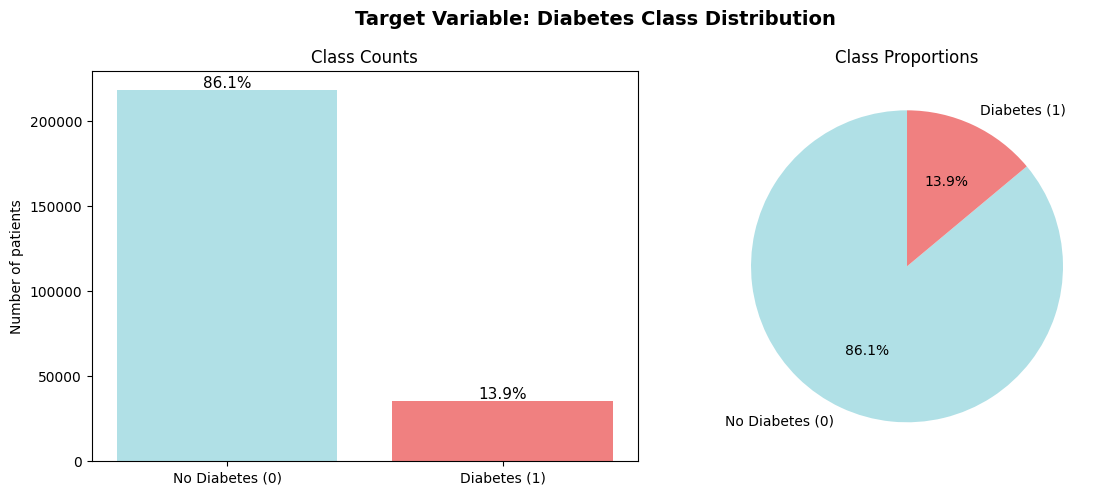

In [ ]:
# visualization for the class imbalance

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Target Variable: Diabetes Class Distribution', fontsize=14, fontweight='bold')

# Plot 1: count bar chart
labels = ['No Diabetes (0)', 'Diabetes (1)']
colors = ['powderblue', 'lightcoral']
axes[0].bar(labels, class_counts.values, color=colors)
axes[0].set_title('Class Counts')
axes[0].set_ylabel('Number of patients')

# adding percentage labels on top of each bar
for i, (count, pct) in enumerate(zip(class_counts.values, class_pcts.values)):
    axes[0].text(i, count + 1000, f'{pct:.1f}%', ha='center', fontsize=11)


# Plot 2: pie chart showing proportions clearly
axes[1].pie(
    class_counts.values,
    labels=labels,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90
)
axes[1].set_title('Class Proportions')

plt.tight_layout()
plt.show()

##### Important observations:

- The dataset is very imbalanced, 86% of patients do not have diabities, only 14% do
- A naive model that always predicts no diabetes would achieve 86% accuracy, which is highly misleading
- this means we must use SMOTE to rebalance the training set before fitting any models
- We will also rely on F1, ROC-AUC and Precision-Recall curves rather than just using accuracy as our evaluation metrics

### 2.2 Feature distributions

Now we look at each feature individually. The dataset is a mix of mostly binary features and then some ordinal integer features. We visualize them separately to understand their distributions.

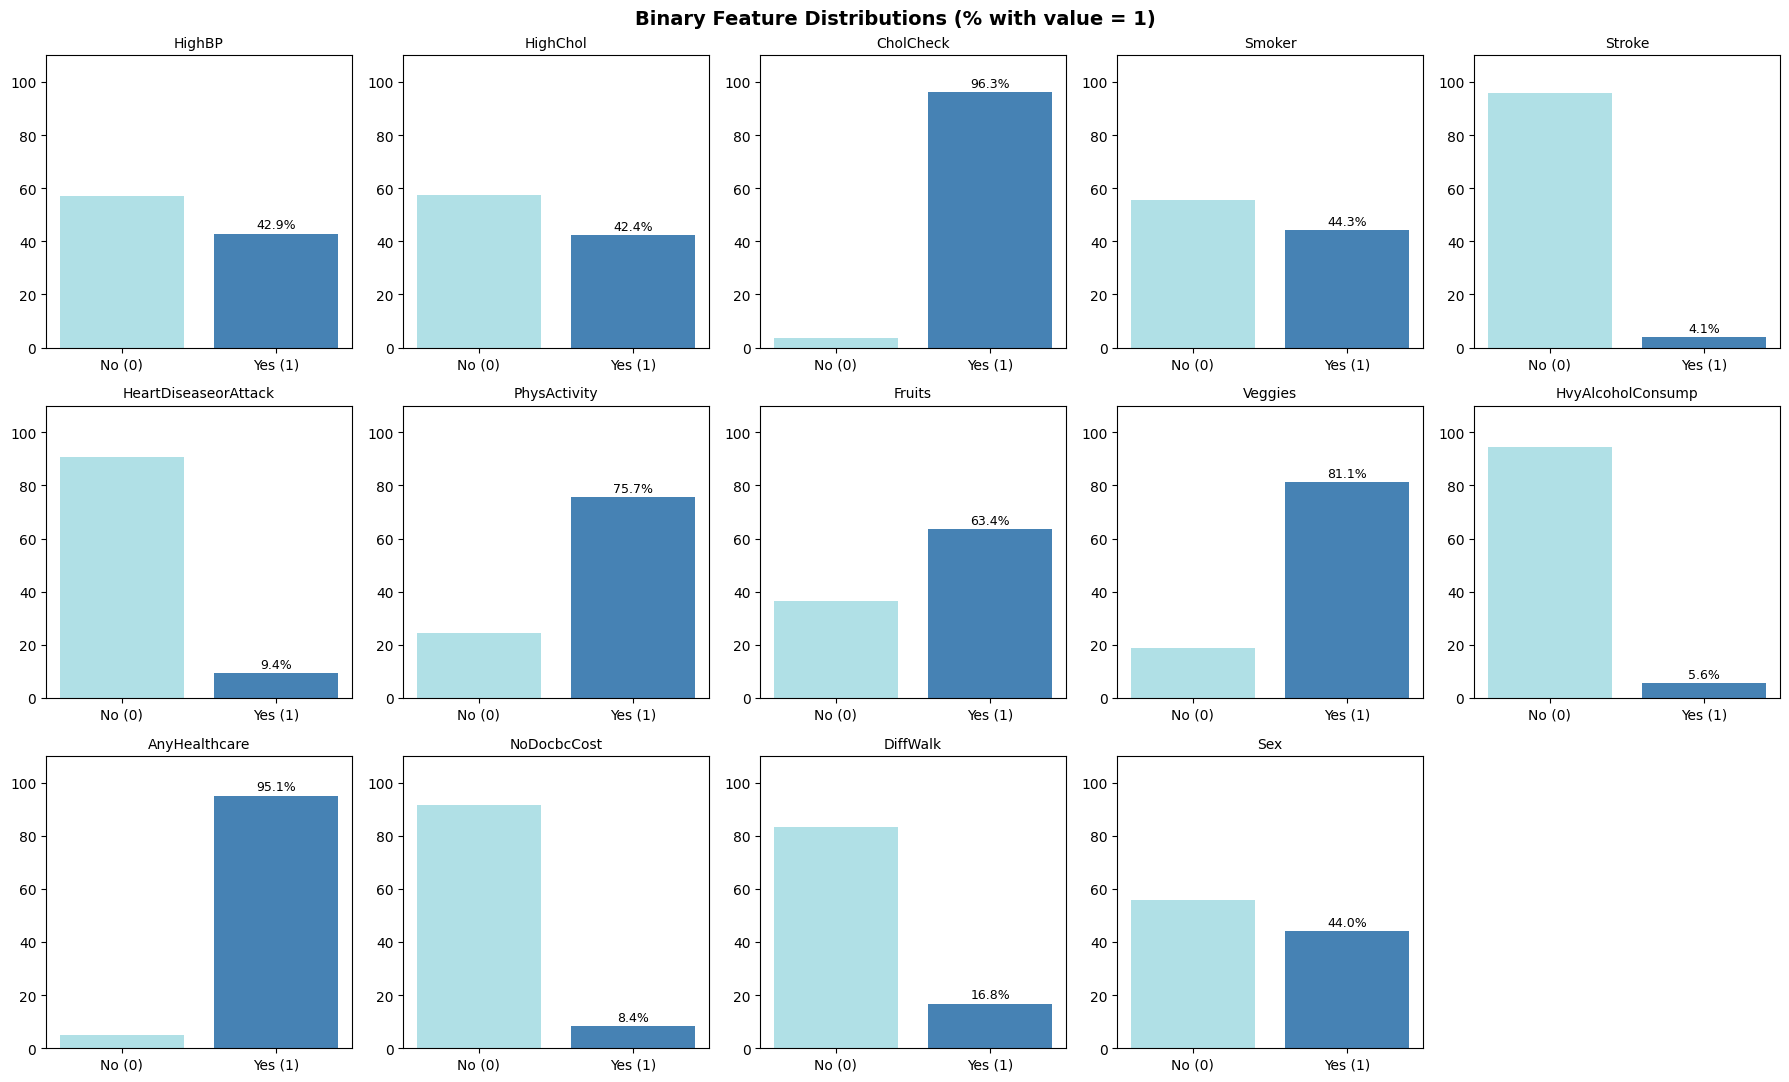

In [ ]:
# visualizing the binary features, we look at what proportion of patients have each risk factor, such as what % have high blood pressure?

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
fig.suptitle('Binary Feature Distributions (% with value = 1)', fontsize=14, fontweight='bold')

axes = axes.flatten()

for i, feat in enumerate(binary_features):
    pct = df[feat].mean() * 100  # mean of a 0/1 column = proportion with value 1
    axes[i].bar(['No (0)', 'Yes (1)'],
                [100 - pct, pct],
                color=['powderblue', 'steelblue'])
    axes[i].set_title(feat, fontsize=10)
    axes[i].set_ylim(0, 110)
    axes[i].text(1, pct + 2, f'{pct:.1f}%', ha='center', fontsize=9)

# hiding the last empty subplot
for j in range(len(binary_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

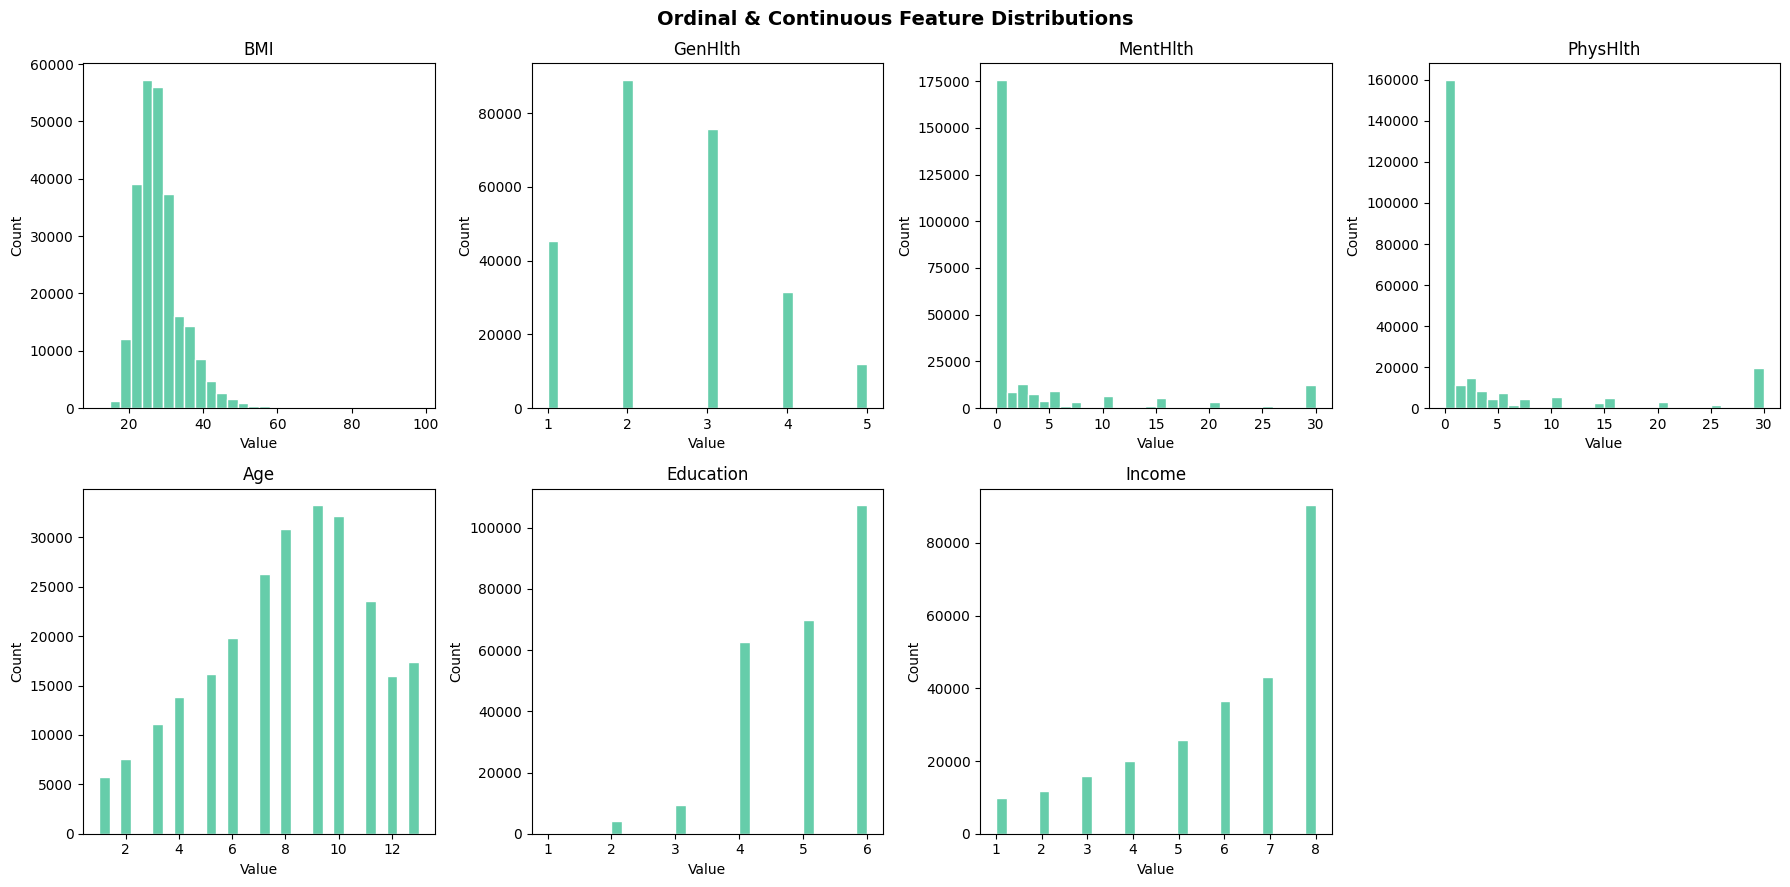

In [ ]:
# visualizing the ordinal/continuous features
# making histograms for the distributions

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Ordinal & Continuous Feature Distributions', fontsize=14, fontweight='bold')

axes = axes.flatten()

for i, feat in enumerate(ordinal_features):
    axes[i].hist(df[feat], bins=30, color='mediumaquamarine', edgecolor='white')
    axes[i].set_title(feat)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')

# hiding the last empty subplot
for j in range(len(ordinal_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### 2.3 Feature correlations

As next step we check for multicollinearity between features. This is because highly correlated features carry redundant information and can destabilize some models (like logistic regression).

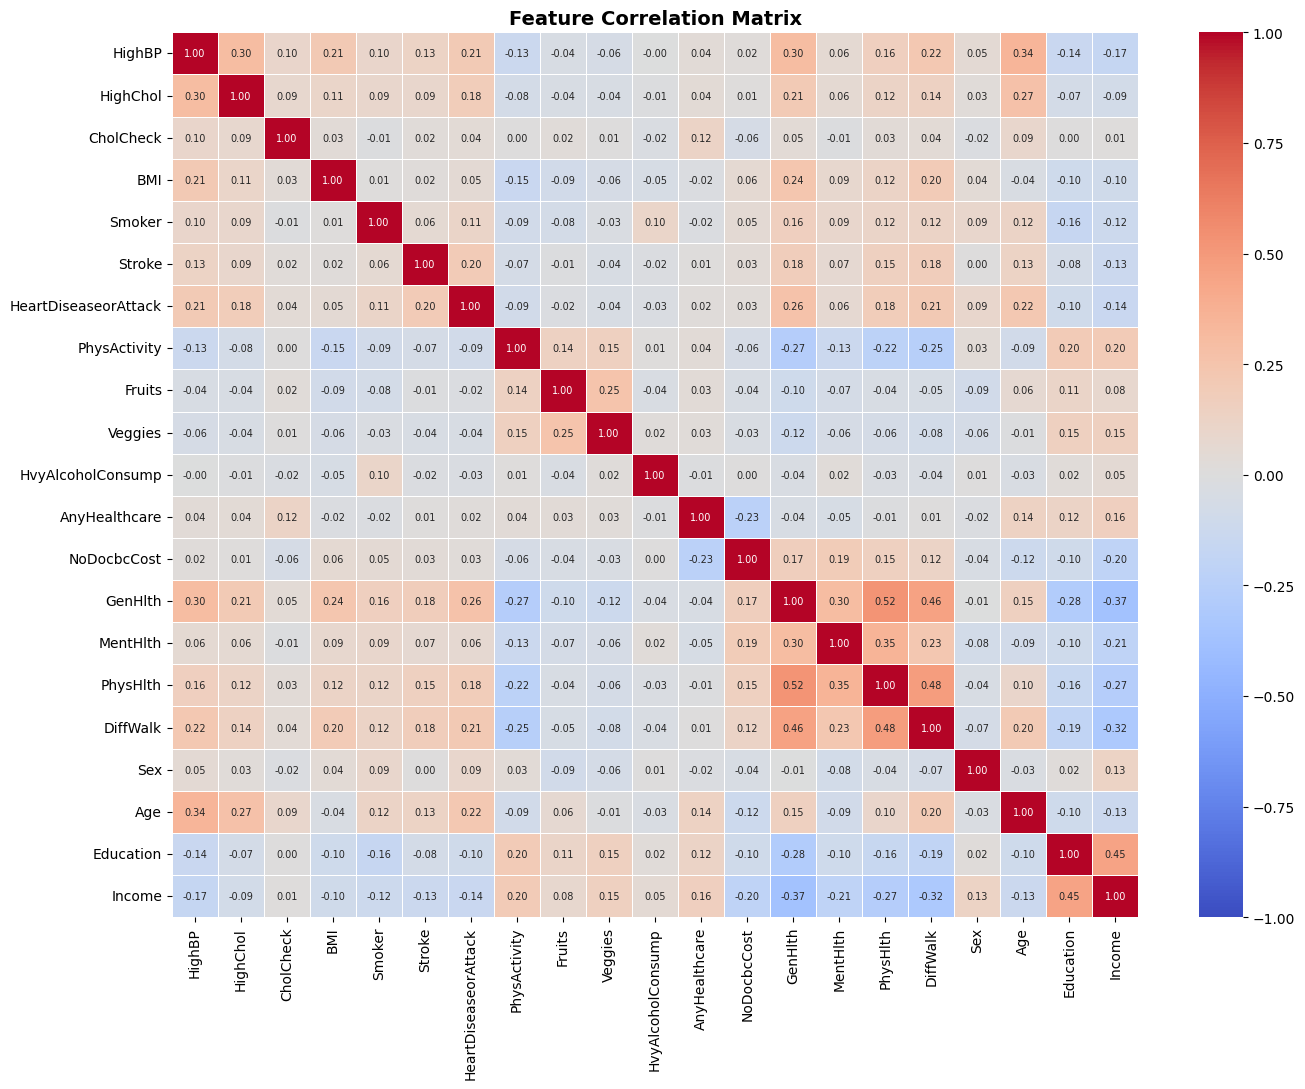

In [ ]:
# Correlation heatmap for all features
# We are looking for any features that are very highly correlated (>0.7) with each other
# These would be candidates for removal or dimensionality reduction

fig, ax = plt.subplots(figsize=(14, 11))

corr_matrix = X_raw.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    annot_kws={'size': 7},
    linewidths=0.5
)

ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 BMI distribution by age group

We will look at how BMI varies across age groups split by diabetes status. This gives us insight into how two of our strongest predictors interact with each other.


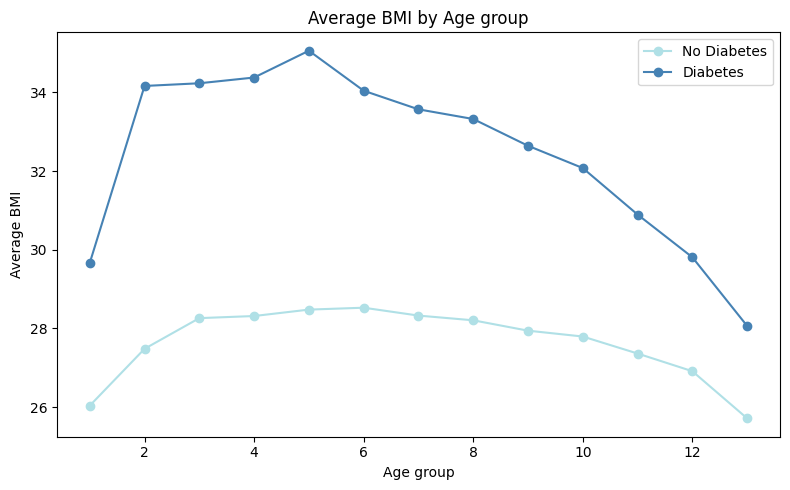

In [ ]:
# plotting average BMI per age group, split by diabetes status
# this shows how the two strongest predictors interact with each other

fig, ax = plt.subplots(figsize=(8, 5))

for label, color, name in zip([0, 1], ['powderblue', 'steelblue'], ['No Diabetes', 'Diabetes']):
    df[df[TARGET] == label].groupby('Age')['BMI'].mean().plot(
        ax=ax, label=name, color=color, marker='o')

ax.set_title('Average BMI by Age group')
ax.set_xlabel('Age group')
ax.set_ylabel('Average BMI')
ax.legend()

plt.tight_layout()
plt.show()

### 2.5 Diabetes rate by income

Next, we are looking at diabetes prevalence across income brackets,so we can spot some interesting socioeconomic patterns in the data.


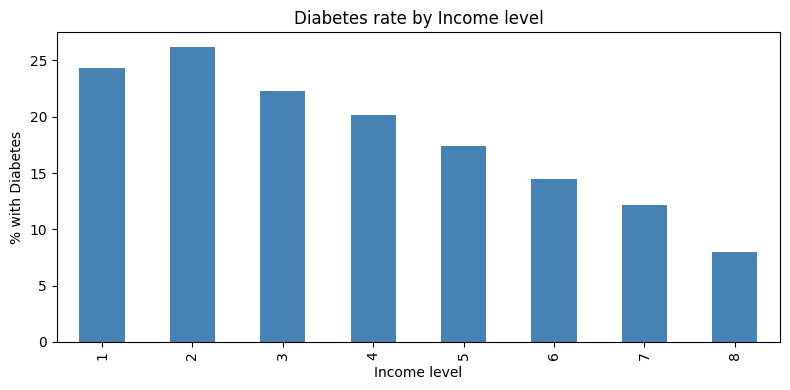

In [ ]:
# diabetes prevalence across income brackets
# one of the strongest gradients in the dataset

income_rate = df.groupby('Income')[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))

income_rate.plot.bar(ax=ax, color='steelblue')
ax.set_title('Diabetes rate by Income level')
ax.set_xlabel('Income level')
ax.set_ylabel('% with Diabetes')

plt.tight_layout()
plt.show()

### 2.6 Risk Ratio Table

For each binary feature we compute a risk ratio to see how many times more likely someone is to have diabetes when the feature is present vs. absent. This gives us a nice summary of the binary feature analysis in one ranked table.


In [ ]:
rows = []

for col in binary_features:
    r0 = df[df[TARGET] == 0][col].mean() * 100
    r1 = df[df[TARGET] == 1][col].mean() * 100
    rows.append({
        "feature": col,
        "type": "binary",
        "no_diabetes": f"{r0:.1f}%",
        "diabetes": f"{r1:.1f}%",
        "risk_ratio": round(r1 / r0, 2) if r0 > 0 else None
    })

for col in ordinal_features:
    m0 = df[df[TARGET] == 0][col].mean()
    m1 = df[df[TARGET] == 1][col].mean()
    rows.append({
        "feature": col,
        "type": "continuous/ordinal",
        "no_diabetes": f"mean {m0:.2f}",
        "diabetes": f"mean {m1:.2f}",
        "risk_ratio": None
    })

summary_df = (pd.DataFrame(rows)
              .sort_values("risk_ratio", ascending=False, na_position="last")
              .reset_index(drop=True))

# highlighting risk ratios: yellow = high risk, blue = protective
def highlight_risk(val):
    if not isinstance(val, float):
        return ""
    if val >= 2.0:   return "background-color: #F9E79F"
    if val < 1.0:    return "background-color: #AED6F1"
    return ""

(summary_df.style
    .map(highlight_risk, subset=["risk_ratio"])
    .hide(axis="index")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th",
                        "props": [("text-align", "center"),
                                  ("background-color", "#f5f5f5")]}]))

feature,type,no_diabetes,diabetes,risk_ratio
HeartDiseaseorAttack,binary,7.3%,22.3%,3.040000
Stroke,binary,3.2%,9.2%,2.870000
DiffWalk,binary,13.5%,37.1%,2.740000
HighBP,binary,37.7%,75.3%,2.000000
HighChol,binary,38.4%,67.0%,1.740000
NoDocbcCost,binary,8.1%,10.6%,1.310000
Smoker,binary,43.1%,51.8%,1.200000
Sex,binary,43.4%,47.9%,1.100000
CholCheck,binary,95.8%,99.3%,1.040000
AnyHealthcare,binary,95.0%,96.0%,1.010000


### 2.7 Feature distributions split by diabetes status

Here we compare how each feature differs between diabetic and non-diabetic patients. This gives us an early intuition about which features are likely to be most predictive.

In [ ]:
# Mean value of each feature split by diabetes label
# For binary features this shows the proportion with that risk factor in each class
# For ordinal features this shows the average value — e.g. average BMI for diabetics vs non-diabetics

feature_means = df.groupby('Diabetes_binary')[ordinal_features + binary_features].mean().T
feature_means.columns = ['No Diabetes', 'Diabetes']
feature_means['Difference'] = feature_means['Diabetes'] - feature_means['No Diabetes']
feature_means = feature_means.sort_values('Difference', ascending=False)

print("Feature means by class (sorted by difference):")
display(feature_means.round(3))

Feature means by class (sorted by difference):


,No Diabetes,Diabetes,Difference
PhysHlth,3.641,7.954,4.313
BMI,27.806,31.944,4.138
Age,7.814,9.379,1.565
MentHlth,2.978,4.462,1.484
GenHlth,2.385,3.291,0.906
HighBP,0.377,0.753,0.376
HighChol,0.384,0.670,0.286
DiffWalk,0.135,0.371,0.236
HeartDiseaseorAttack,0.073,0.223,0.150
Smoker,0.431,0.518,0.087


Next, we split the features into three groups for analysis: clinical risk, lifestyle factors, and socioeconomic factors.

### 2.8 Health Risk

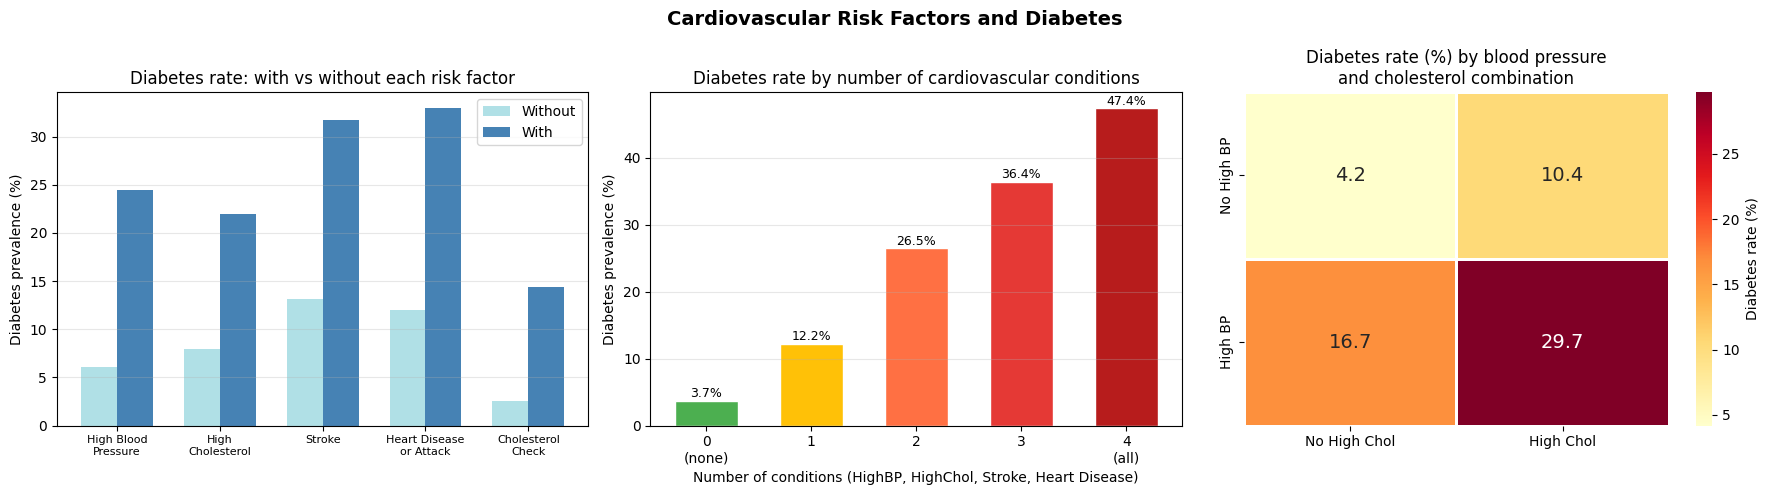

In [ ]:
# cardiovascular risk factors and diabetes
# three simple charts showing how each CV factor relates to diabetes risk

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Cardiovascular Risk Factors and Diabetes', fontsize=14, fontweight='bold')

# -----------------------------------------------------------------------

# Plot 1: diabetes rate for each individual cardiovascular risk factor
# simple comparison of how much each factor raises risk on its own

cv_features = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'CholCheck']
cv_labels   = ['High Blood\nPressure', 'High\nCholesterol', 'Stroke', 'Heart Disease\nor Attack', 'Cholesterol\nCheck']

rates_present = [df[df[feat] == 1]['Diabetes_binary'].mean() * 100 for feat in cv_features]
rates_absent  = [df[df[feat] == 0]['Diabetes_binary'].mean() * 100 for feat in cv_features]

x = np.arange(len(cv_features))
width = 0.35

axes[0].bar(x - width/2, rates_absent,  width, label='Without',  color='powderblue')
axes[0].bar(x + width/2, rates_present, width, label='With',      color='steelblue')
axes[0].set_title('Diabetes rate: with vs without each risk factor')
axes[0].set_ylabel('Diabetes prevalence (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(cv_labels, fontsize=8)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# -----------------------------------------------------------------------

# Plot 2: diabetes rate by number of cardiovascular conditions
# shows the compounding effect of having multiple risk factors at once

df['cv_count'] = df[['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack']].sum(axis=1)
cv_count_rate  = df.groupby('cv_count')['Diabetes_binary'].mean() * 100

axes[1].bar(cv_count_rate.index, cv_count_rate.values,
            color=['#4CAF50', '#FFC107', '#FF7043', '#E53935', '#B71C1C'],
            edgecolor='white', width=0.6)
axes[1].set_title('Diabetes rate by number of cardiovascular conditions')
axes[1].set_xlabel('Number of conditions (HighBP, HighChol, Stroke, Heart Disease)')
axes[1].set_ylabel('Diabetes prevalence (%)')
axes[1].set_xticks([0, 1, 2, 3, 4])
axes[1].set_xticklabels(['0\n(none)', '1', '2', '3', '4\n(all)'])
axes[1].grid(axis='y', alpha=0.3)

# adding percentage labels on each bar
for i, val in zip(cv_count_rate.index, cv_count_rate.values):
    axes[1].text(i, val + 0.5, f'{val:.1f}%', ha='center', fontsize=9)

df.drop(columns=['cv_count'], inplace=True)

# -----------------------------------------------------------------------

# Plot 3: simple 2x2 heatmap — HighBP x HighChol combination
# just 4 cells so it is immediately readable unlike the original complex version

heatmap_data = df.groupby(['HighBP', 'HighChol'])['Diabetes_binary'].mean() * 100
heatmap_data = heatmap_data.unstack()
heatmap_data.index   = ['No High BP', 'High BP']
heatmap_data.columns = ['No High Chol', 'High Chol']

sns.heatmap(
    heatmap_data,
    ax=axes[2],
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=2,
    linecolor='white',
    annot_kws={'size': 14},
    cbar_kws={'label': 'Diabetes rate (%)'}
)
axes[2].set_title('Diabetes rate (%) by blood pressure\nand cholesterol combination')
axes[2].set_xlabel('')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

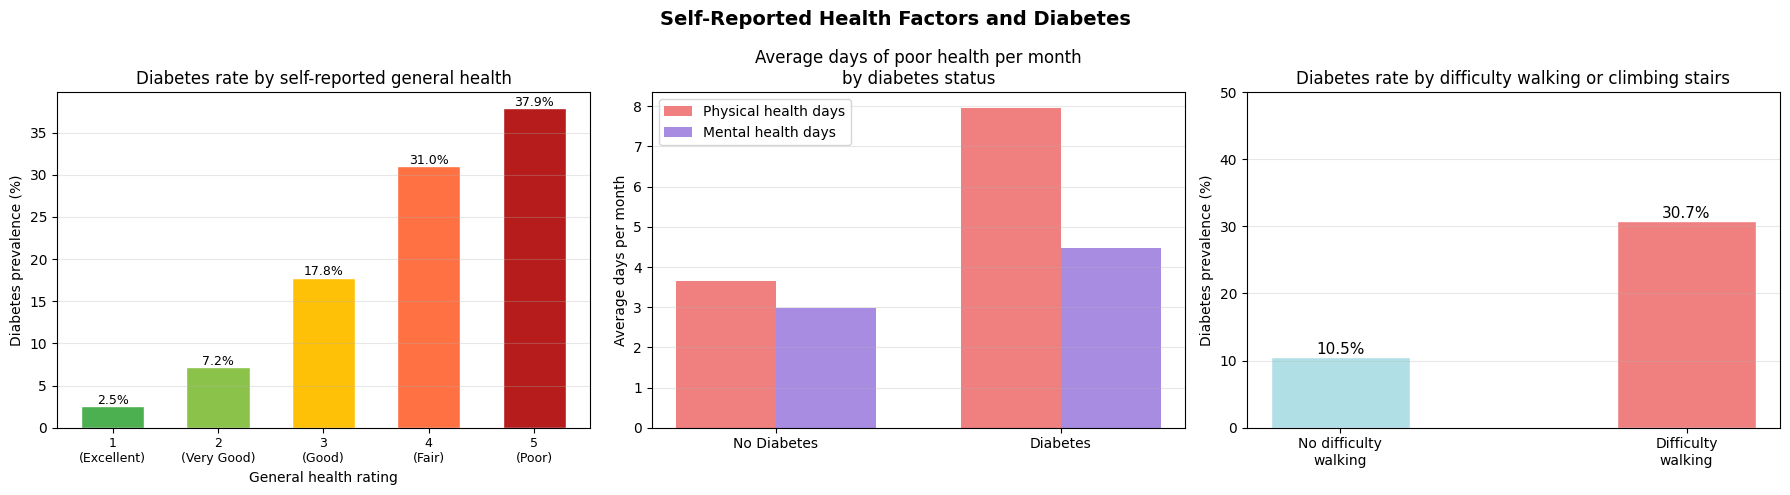

In [ ]:
# self-reported health factors and diabetes
# three simple charts showing how general health, physical health and mobility relate to diabetes

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Self-Reported Health Factors and Diabetes', fontsize=14, fontweight='bold')

# -----------------------------------------------------------------------

# Plot 1: diabetes rate by general health rating
# GenHlth goes from 1 (excellent) to 5 (poor) — the clearest single predictor in the dataset

genhlth_rate = df.groupby('GenHlth')['Diabetes_binary'].mean() * 100
labels = ['1\n(Excellent)', '2\n(Very Good)', '3\n(Good)', '4\n(Fair)', '5\n(Poor)']
colors = ['#4CAF50', '#8BC34A', '#FFC107', '#FF7043', '#B71C1C']

bars = axes[0].bar(genhlth_rate.index, genhlth_rate.values,
                   color=colors, edgecolor='white', width=0.6)
axes[0].set_title('Diabetes rate by self-reported general health')
axes[0].set_xlabel('General health rating')
axes[0].set_ylabel('Diabetes prevalence (%)')
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xticklabels(labels, fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

for bar, val in zip(bars, genhlth_rate.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=9)

# -----------------------------------------------------------------------

# Plot 2: average days of poor physical and mental health by diabetes status
# comparing how many days per month each group reports feeling unwell

health_means = df.groupby('Diabetes_binary')[['PhysHlth', 'MentHlth']].mean()

x = np.arange(2)
width = 0.35

axes[1].bar(x - width/2, health_means['PhysHlth'].values, width,
            label='Physical health days', color='lightcoral')
axes[1].bar(x + width/2, health_means['MentHlth'].values, width,
            label='Mental health days', color='mediumpurple', alpha=0.8)
axes[1].set_title('Average days of poor health per month\nby diabetes status')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['No Diabetes', 'Diabetes'])
axes[1].set_ylabel('Average days per month')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

# -----------------------------------------------------------------------

# Plot 3: diabetes rate by difficulty walking
# DiffWalk is a simple binary flag but shows a strong signal

diffwalk_rate = df.groupby('DiffWalk')['Diabetes_binary'].mean() * 100

bars = axes[2].bar(['No difficulty\nwalking', 'Difficulty\nwalking'],
                   diffwalk_rate.values,
                   color=['powderblue', 'lightcoral'],
                   edgecolor='white', width=0.4)
axes[2].set_title('Diabetes rate by difficulty walking or climbing stairs')
axes[2].set_ylabel('Diabetes prevalence (%)')
axes[2].set_ylim(0, 50)
axes[2].grid(axis='y', alpha=0.3)

for bar, val in zip(bars, diffwalk_rate.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, val + 0.5,
                 f'{val:.1f}%', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

## 2.9 Lifestyle Features

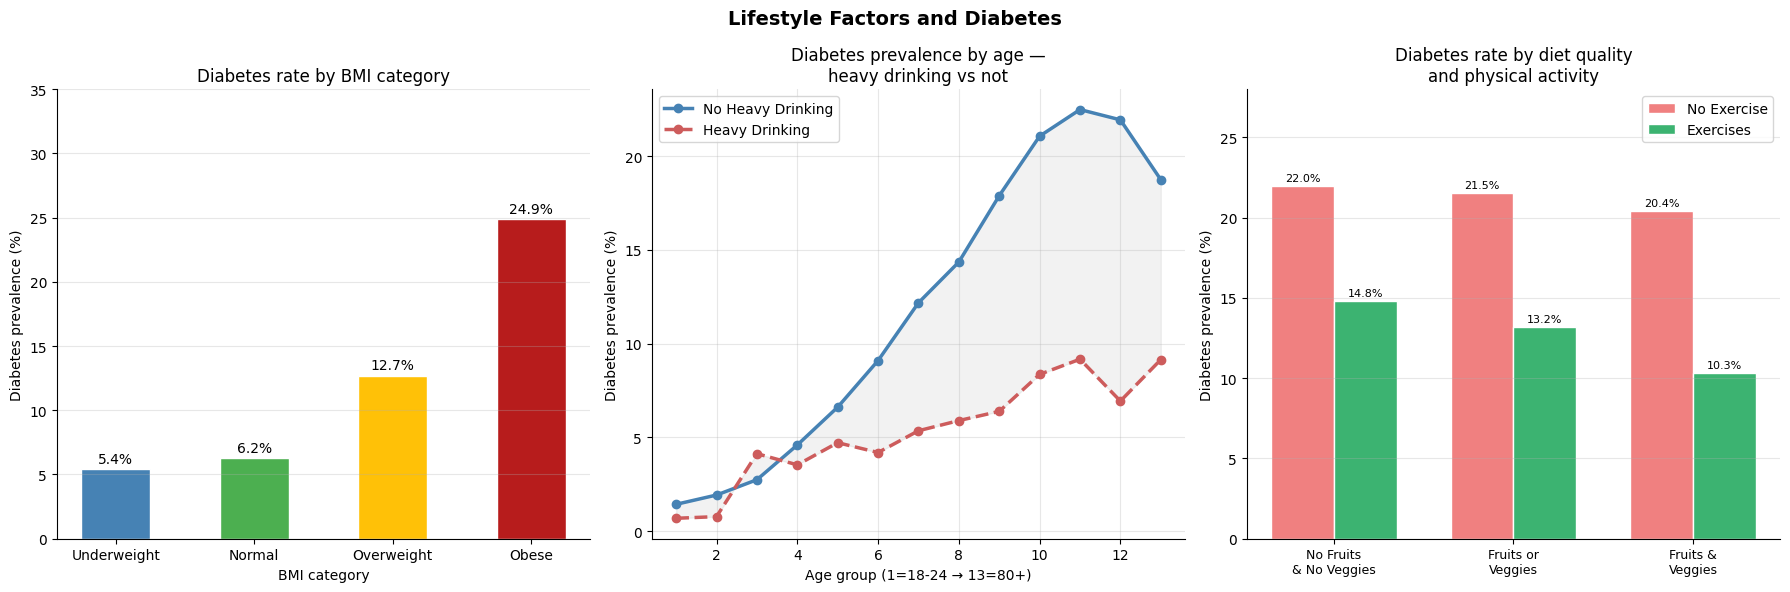

In [ ]:
# lifestyle factors and diabetes
# bar chart for BMI, keeping the middle alcohol chart, dumbbell for diet vs exercise

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Lifestyle Factors and Diabetes', fontsize=14, fontweight='bold')

# -----------------------------------------------------------------------

# Plot 1: bar chart — diabetes rate by BMI category
# simple and clear — shows how obesity dramatically raises risk compared to other groups

df['BMI_cat'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 100],
                        labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

bmi_rate = df.groupby('BMI_cat', observed=True)['Diabetes_binary'].mean() * 100
colors   = ['steelblue', '#4CAF50', '#FFC107', '#B71C1C']

bars = axes[0].bar(bmi_rate.index, bmi_rate.values,
                   color=colors, edgecolor='white', width=0.5)

axes[0].set_title('Diabetes rate by BMI category')
axes[0].set_xlabel('BMI category')
axes[0].set_ylabel('Diabetes prevalence (%)')
axes[0].set_ylim(0, 35)
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for bar, val in zip(bars, bmi_rate.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.5,
                 f'{val:.1f}%', ha='center', fontsize=10)

df.drop(columns=['BMI_cat'], inplace=True)

# -----------------------------------------------------------------------

# Plot 2: keeping the original alcohol × age line chart — it tells a clear story

alcohol_age = df.groupby(['Age', 'HvyAlcoholConsump'])['Diabetes_binary'].mean() * 100
alcohol_age = alcohol_age.unstack()
alcohol_age.columns = ['No Heavy Drinking', 'Heavy Drinking']

axes[1].fill_between(alcohol_age.index, alcohol_age['No Heavy Drinking'],
                     alcohol_age['Heavy Drinking'], alpha=0.1, color='gray')
axes[1].plot(alcohol_age.index, alcohol_age['No Heavy Drinking'],
             color='steelblue', marker='o', lw=2.5, label='No Heavy Drinking')
axes[1].plot(alcohol_age.index, alcohol_age['Heavy Drinking'],
             color='indianred', marker='o', lw=2.5, label='Heavy Drinking', linestyle='--')

axes[1].set_title('Diabetes prevalence by age —\nheavy drinking vs not')
axes[1].set_xlabel('Age group (1=18-24 → 13=80+)')
axes[1].set_ylabel('Diabetes prevalence (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Plot 3: grouped bar chart — exercise vs no exercise for each diet quality level
# makes it easy to compare the exercise effect within each diet group

df['Diet_score'] = df['Fruits'] + df['Veggies']
diet_labels = ['No Fruits\n& No Veggies', 'Fruits or\nVeggies', 'Fruits &\nVeggies']

no_exercise = [df[(df['Diet_score'] == d) & (df['PhysActivity'] == 0)]['Diabetes_binary'].mean() * 100
               for d in [0, 1, 2]]
exercises   = [df[(df['Diet_score'] == d) & (df['PhysActivity'] == 1)]['Diabetes_binary'].mean() * 100
               for d in [0, 1, 2]]

x     = np.arange(3)
width = 0.35

bars1 = axes[2].bar(x - width/2, no_exercise, width,
                    label='No Exercise', color='lightcoral', edgecolor='white')
bars2 = axes[2].bar(x + width/2, exercises,   width,
                    label='Exercises',   color='mediumseagreen', edgecolor='white')

axes[2].set_title('Diabetes rate by diet quality\nand physical activity')
axes[2].set_xticks(x)
axes[2].set_xticklabels(diet_labels, fontsize=9)
axes[2].set_ylabel('Diabetes prevalence (%)')
axes[2].set_ylim(0, 28)
axes[2].legend()
axes[2].grid(axis='y', alpha=0.3)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

for bar, val in zip(bars1, no_exercise):
    axes[2].text(bar.get_x() + bar.get_width()/2, val + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=8)
for bar, val in zip(bars2, exercises):
    axes[2].text(bar.get_x() + bar.get_width()/2, val + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=8)

df.drop(columns=['Diet_score'], inplace=True)

plt.tight_layout()
plt.show()

## 2.10 Socioeconomic Features

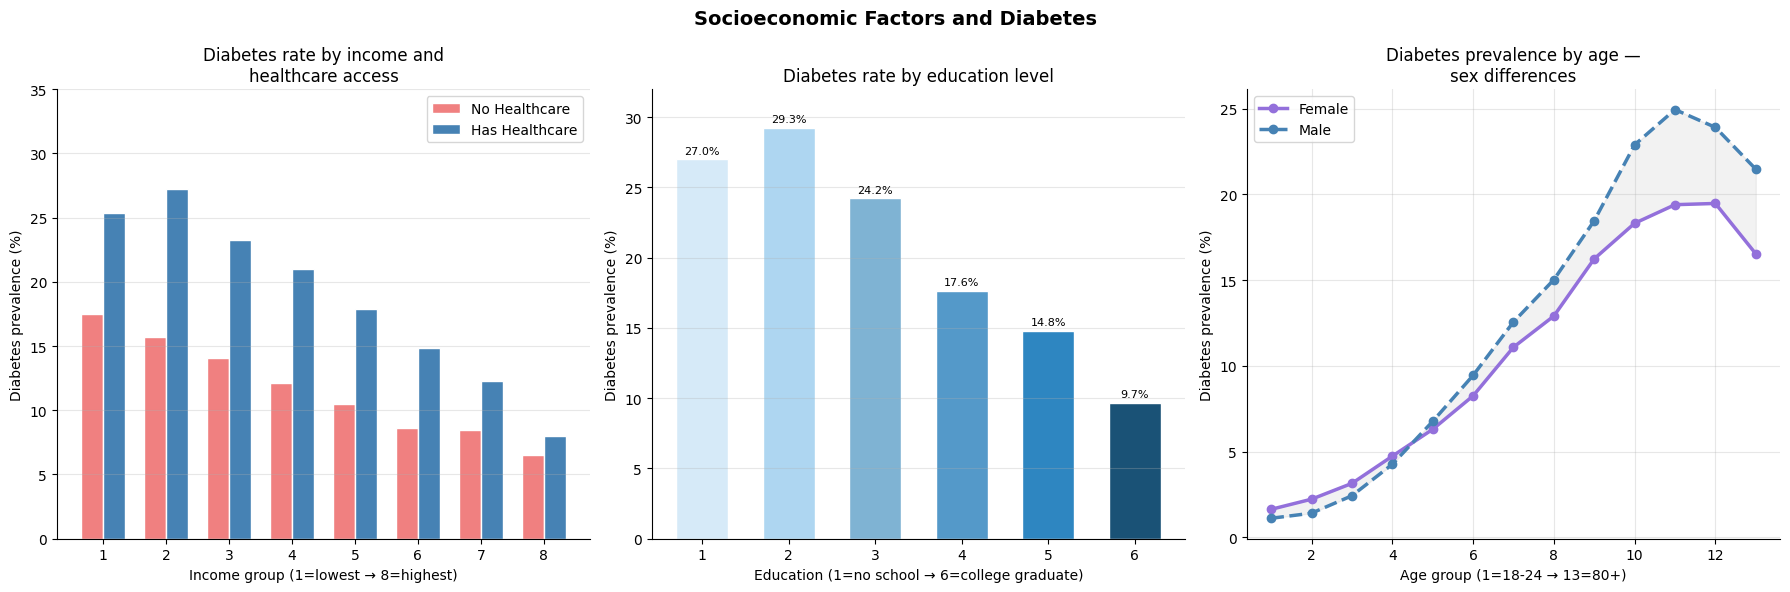

In [ ]:
# socioeconomic factors and diabetes
# income + healthcare combined, education, age by sex

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Socioeconomic Factors and Diabetes', fontsize=14, fontweight='bold')

# -----------------------------------------------------------------------

# Plot 1: grouped bar — diabetes rate by income, split by healthcare access
# two bars per income group shows both the income gradient and the healthcare gap at once

no_healthcare  = [df[(df['Income'] == i) & (df['AnyHealthcare'] == 0)]['Diabetes_binary'].mean() * 100
                  for i in range(1, 9)]
has_healthcare = [df[(df['Income'] == i) & (df['AnyHealthcare'] == 1)]['Diabetes_binary'].mean() * 100
                  for i in range(1, 9)]

x     = np.arange(8)
width = 0.35

axes[0].bar(x - width/2, no_healthcare,  width, label='No Healthcare',
            color='lightcoral', edgecolor='white')
axes[0].bar(x + width/2, has_healthcare, width, label='Has Healthcare',
            color='steelblue',  edgecolor='white')
axes[0].set_title('Diabetes rate by income and\nhealthcare access')
axes[0].set_xlabel('Income group (1=lowest → 8=highest)')
axes[0].set_ylabel('Diabetes prevalence (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(range(1, 9))
axes[0].legend()
axes[0].set_ylim(0, 35)
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# -----------------------------------------------------------------------

# Plot 2: bar chart — diabetes rate by education level

education_rate = df.groupby('Education')['Diabetes_binary'].mean() * 100
colors_edu = ['#1A5276', '#2E86C1', '#5499C9', '#7FB3D3', '#AED6F1', '#D6EAF8']

bars = axes[1].bar(education_rate.index, education_rate.values,
                   color=colors_edu[::-1], edgecolor='white', width=0.6)
axes[1].set_title('Diabetes rate by education level')
axes[1].set_xlabel('Education (1=no school → 6=college graduate)')
axes[1].set_ylabel('Diabetes prevalence (%)')
axes[1].set_ylim(0, 32)
axes[1].grid(axis='y', alpha=0.3)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

for bar, val in zip(bars, education_rate.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.4,
                 f'{val:.1f}%', ha='center', fontsize=8)

# -----------------------------------------------------------------------

# Plot 3: line chart — diabetes rate by age, split by sex

sex_age = df.groupby(['Age', 'Sex'])['Diabetes_binary'].mean() * 100
sex_age = sex_age.unstack()
sex_age.columns = ['Female', 'Male']

axes[2].fill_between(sex_age.index, sex_age['Female'],
                     sex_age['Male'], alpha=0.1, color='gray')
axes[2].plot(sex_age.index, sex_age['Female'],
             color='mediumpurple', marker='o', lw=2.5, label='Female')
axes[2].plot(sex_age.index, sex_age['Male'],
             color='steelblue', marker='o', lw=2.5, label='Male', linestyle='--')
axes[2].set_title('Diabetes prevalence by age —\nsex differences')
axes[2].set_xlabel('Age group (1=18-24 → 13=80+)')
axes[2].set_ylabel('Diabetes prevalence (%)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

Before building any models we prepare the data including scaling features, splitting into train and test sets, and setting up cross-validation. Everything is done before modelling so the test set stays completely untouched and our results are reliable.

In [ ]:
# separating features and target into numpy arrays

X = X_raw.copy().values           # numpy array of shape (253680, 21)
y = y_raw.values.ravel()          # flat 1D array of labels

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Class counts — 0: {(y==0).sum():,}   1: {(y==1).sum():,}")

X shape: (253680, 21)
y shape: (253680,)
Class counts — 0: 218,334   1: 35,346


In [ ]:
# 80/20 train/test split with stratification so both sets keep the same class ratio

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # ensures both splits have ~86%/14% class ratio
)

print(f"Training set:   {X_train.shape[0]:,} samples")
print(f"Test set:       {X_test.shape[0]:,} samples")
print()
print(f"Train class balance — 0: {(y_train==0).sum():,}  1: {(y_train==1).sum():,}")
print(f"Test class balance  — 0: {(y_test==0).sum():,}   1: {(y_test==1).sum():,}")

Training set:   202,944 samples
Test set:       50,736 samples

Train class balance — 0: 174,667  1: 28,277
Test class balance  — 0: 43,667   1: 7,069


In [ ]:
# scaling features to mean=0 and std=1
# fitting only on training data — applying the same scaler to test to avoid data leakage

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # fit + transform on train
X_test_scaled  = scaler.transform(X_test)         # transform only on test

print("Scaling complete.")
print(f"Train feature means (first 3):  {X_train_scaled.mean(axis=0)[:3].round(4)}")
print(f"Train feature stds  (first 3):  {X_train_scaled.std(axis=0)[:3].round(4)}")

Scaling complete.
Train feature means (first 3):  [-0. -0. -0.]
Train feature stds  (first 3):  [1. 1. 1.]


In [ ]:
# setting up 5-fold stratified cross-validation
# stratified so each fold keeps the same class ratio as the full dataset

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Cross-validation setup:")
print(f"  Strategy: Stratified K-Fold")
print(f"  Folds:    5")
print(f"  Shuffle:  True")

Cross-validation setup:
  Strategy: Stratified K-Fold
  Folds:    5
  Shuffle:  True


## 4. Handling class imbalance with SMOTE

Another crucial step of data preparation is to handle class imbalance. With a 86:14 class split, any model will just learn to always predict "no diabetes" and still get 86% accuracy. SMOTE fixes this by generating synthetic minority class samples in the training set so the model sees a balanced distribution. We only apply it to the training data, so the test set stays untouched to reflect the real world.

In [ ]:
# applying SMOTE to balance the training set
# generates synthetic minority samples by interpolating between existing ones

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE resampling:")
print(f"  Training set size: {len(X_train_smote):,}")
print(f"  Class 0 (no diabetes): {(y_train_smote==0).sum():,}")
print(f"  Class 1 (diabetes):    {(y_train_smote==1).sum():,}")

After SMOTE resampling:
  Training set size: 349,334
  Class 0 (no diabetes): 174,667
  Class 1 (diabetes):    174,667


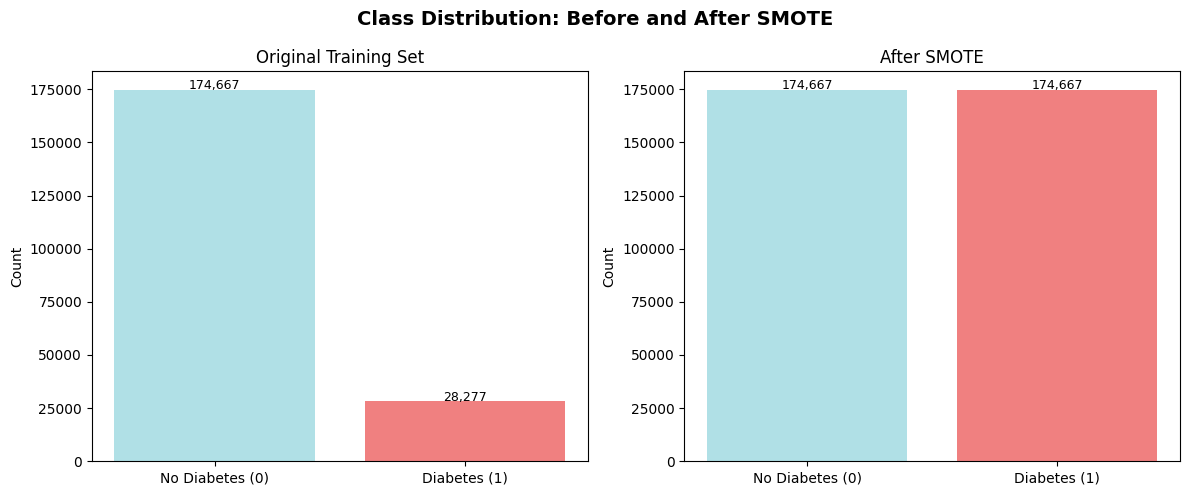

In [ ]:
# visualising the class balance before and after SMOTE

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Class Distribution: Before and After SMOTE', fontsize=14, fontweight='bold')

for ax, (title, labels) in zip(axes, [
    ('Original Training Set', y_train),
    ('After SMOTE',           y_train_smote)
]):
    counts = pd.Series(labels).value_counts()
    bars = ax.bar(['No Diabetes (0)', 'Diabetes (1)'],
                  [counts.get(0, 0), counts.get(1, 0)],
                  color=['powderblue', 'lightcoral'])
    ax.set_title(title)
    ax.set_ylabel('Count')
    for bar, count in zip(bars, [counts.get(0, 0), counts.get(1, 0)]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                f'{count:,}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

##### Important observations:

- SMOTE successfully balances the training set from 86:14 to 50:50 by generating synthetic minority class samples
- The test set remains untouched and still reflects the real-world class distribution (~86:14)
- We will rely on **F1, ROC-AUC, and Precision-Recall curves** rather than accuracy as our evaluation metrics, since accuracy is misleading when classes are imbalanced

## 5. Baseline Machine Learning Models

We train and compare six classical ML models (Logistic Regression, KNN, Decision Tree, Random Forest, Gradient Boosting and SVM), each representing a different classification approach. All models are trained on the SMOTE-balanced training set and evaluated on the original imbalanced test set to get a realistic picture of performance. For each model we report accuracy, precision, recall, F1, and ROC-AUC.

In [ ]:
# helper function so we don't repeat the same evaluation code for every model
# PR-AUC is our primary metric — it is more informative than ROC-AUC when classes are imbalanced

import time

def evaluate_model(model, X_tr, y_tr, X_te, y_te, model_name):
    """Fits model, evaluates on test set, returns metrics dict + ROC curve data."""

    start_time = time.time()
    model.fit(X_tr, y_tr)
    runtime = round(time.time() - start_time, 2)

    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else None

    metrics = {
        'Model':     model_name,
        'Runtime (s)': runtime,
        'Accuracy':  round(accuracy_score(y_te, y_pred), 4),
        'Precision': round(precision_score(y_te, y_pred), 4),
        'Recall':    round(recall_score(y_te, y_pred), 4),
        'F1':        round(f1_score(y_te, y_pred), 4),
        'ROC-AUC':   round(roc_auc_score(y_te, y_proba), 4) if y_proba is not None else None,
        'PR-AUC':    round(average_precision_score(y_te, y_proba), 4) if y_proba is not None else None
    }

    # storing ROC curve data for the combined plot later
    fpr, tpr, _ = roc_curve(y_te, y_proba) if y_proba is not None else (None, None, None)

    return metrics, fpr, tpr, model

results_list = []   # appending each model's results here as we go
roc_curves   = {}   # storing ROC curve data for the combined plot

print("Evaluation helper function defined. Ready to train models.")

Evaluation helper function defined. Ready to train models.


### 5.1 Logistic Regression

In [ ]:
# logistic regression — our linear baseline
# C controls regularisation strength, smaller C = stronger regularisation

lr_model = LogisticRegression(
    C=1.0,              # default regularisation strength
    penalty='l2',       # L2 regularisation, shrinks coefficients but keeps all features
    max_iter=1000,
    random_state=42
)

metrics, fpr, tpr, _ = evaluate_model(
    lr_model, X_train_smote, y_train_smote, X_test_scaled, y_test, 'Logistic Regression (L2)'
)

results_list.append(metrics)
roc_curves['Logistic Regression (L2)'] = (fpr, tpr, metrics['ROC-AUC'])

print("Logistic Regression (L2) Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

Logistic Regression (L2) Results:
  Runtime (s): 1.21
  Accuracy: 0.7331
  Precision: 0.3122
  Recall: 0.7614
  F1: 0.4429
  ROC-AUC: 0.8188
  PR-AUC: 0.3898


### 5.2 K-Nearest Neighbours

In [ ]:
# KNN — classifies by majority vote among the k nearest neighbours
# using k=11 (odd number to avoid ties)

knn_model = KNeighborsClassifier(
    n_neighbors=11,        # number of neighbours to consider
    metric='euclidean'     # distance metric
)

metrics, fpr, tpr, _ = evaluate_model(
    knn_model, X_train_smote, y_train_smote, X_test_scaled, y_test, 'KNN'
)

results_list.append(metrics)
roc_curves['KNN'] = (fpr, tpr, metrics['ROC-AUC'])

print("K-Nearest Neighbours Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

K-Nearest Neighbours Results:
  Runtime (s): 0.03
  Accuracy: 0.6939
  Precision: 0.2716
  Recall: 0.7113
  F1: 0.3931
  ROC-AUC: 0.7612
  PR-AUC: 0.3002


### 5.3 Decision Tree

In [ ]:
# single decision tree — interpretable but overfits easily
# limiting max_depth to keep it from memorising the training data

dt_model = DecisionTreeClassifier(
    max_depth=10,         # limiting depth to avoid overfitting
    min_samples_leaf=20,  # each leaf must have at least 20 samples
    random_state=42
)

metrics, fpr, tpr, _ = evaluate_model(
    dt_model, X_train_smote, y_train_smote, X_test_scaled, y_test, 'Decision Tree'
)

results_list.append(metrics)
roc_curves['Decision Tree'] = (fpr, tpr, metrics['ROC-AUC'])

print("Decision Tree Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

Decision Tree Results:
  Runtime (s): 1.83
  Accuracy: 0.8082
  Precision: 0.3656
  Recall: 0.5125
  F1: 0.4268
  ROC-AUC: 0.7979
  PR-AUC: 0.3666


### 5.4 Random Forest

In [ ]:
# random forest — lots of trees trained on random subsets, averaged together
# reduces overfitting compared to a single decision tree

rf_model = RandomForestClassifier(
    n_estimators=100,      # 100 trees in the forest
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1              # using all available CPU cores
)

metrics, fpr, tpr, _ = evaluate_model(
    rf_model, X_train_smote, y_train_smote, X_test_scaled, y_test, 'Random Forest'
)

results_list.append(metrics)
roc_curves['Random Forest'] = (fpr, tpr, metrics['ROC-AUC'])

print("Random Forest Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

Random Forest Results:
  Runtime (s): 35.79
  Accuracy: 0.8142
  Precision: 0.3845
  Recall: 0.5554
  F1: 0.4544
  ROC-AUC: 0.8186
  PR-AUC: 0.3984


### 5.5 Gradient Boosting

In [ ]:
# gradient boosting — trees built sequentially, each one fixing the errors of the last
# usually the strongest classical model but slower to train

gb_model = GradientBoostingClassifier(
    n_estimators=100,      # number of boosting stages
    learning_rate=0.1,     # shrinks the contribution of each tree — lower = more robust but slower
    max_depth=5,
    random_state=42
)

metrics, fpr, tpr, _ = evaluate_model(
    gb_model, X_train_smote, y_train_smote, X_test_scaled, y_test, 'Gradient Boosting'
)

results_list.append(metrics)
roc_curves['Gradient Boosting'] = (fpr, tpr, metrics['ROC-AUC'])

print("Gradient Boosting Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

Gradient Boosting Results:
  Runtime (s): 127.57
  Accuracy: 0.8565
  Precision: 0.4771
  Recall: 0.3116
  F1: 0.377
  ROC-AUC: 0.8222
  PR-AUC: 0.4109


### 5.6 Support Vector Machine (SVM)

In [ ]:
# SVM — finds the decision boundary that maximises the margin between classes
# using RBF kernel for non-linear boundaries
# SVM is O(n^2) so we subsample — 30k balanced samples is enough
from sklearn.utils import resample
X_svm_sample, y_svm_sample = resample(
    X_train_smote, y_train_smote,
    n_samples=30000,   # using 30k balanced samples is enough to get a good boundary
    random_state=42,
    stratify=y_train_smote
)

svm_model = SVC(
    kernel='rbf',        # Radial Basis Function kernel — handles non-linear boundaries
    C=1.0,               # regularisation: smaller C = softer margin (more tolerant of misclassifications)
    gamma='scale',       # gamma controls the influence radius of each training point
    probability=True,    # enables predict_proba so we can compute ROC-AUC
    random_state=42
)

metrics, fpr, tpr, _ = evaluate_model(
    svm_model, X_svm_sample, y_svm_sample, X_test_scaled, y_test, 'SVM (RBF)'
)

results_list.append(metrics)
roc_curves['SVM (RBF)'] = (fpr, tpr, metrics['ROC-AUC'])

print("Support Vector Machine (RBF kernel) Results:")
for k, v in metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

Support Vector Machine (RBF kernel) Results:
  Runtime (s): 171.47
  Accuracy: 0.7294
  Precision: 0.3084
  Recall: 0.7585
  F1: 0.4385
  ROC-AUC: 0.8084
  PR-AUC: 0.3659


In [ ]:
# summary table comparing all classical models

results_df = pd.DataFrame(results_list).set_index('Model')
print("Classical Model Comparison:")
display(results_df.sort_values('ROC-AUC', ascending=False))

Classical Model Comparison:


,Runtime (s),Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
Gradient Boosting,127.57,0.8565,0.4771,0.3116,0.3770,0.8222,0.4109
Logistic Regression (L2),1.21,0.7331,0.3122,0.7614,0.4429,0.8188,0.3898
Random Forest,35.79,0.8142,0.3845,0.5554,0.4544,0.8186,0.3984
SVM (RBF),171.47,0.7294,0.3084,0.7585,0.4385,0.8084,0.3659
Decision Tree,1.83,0.8082,0.3656,0.5125,0.4268,0.7979,0.3666
KNN,0.03,0.6939,0.2716,0.7113,0.3931,0.7612,0.3002


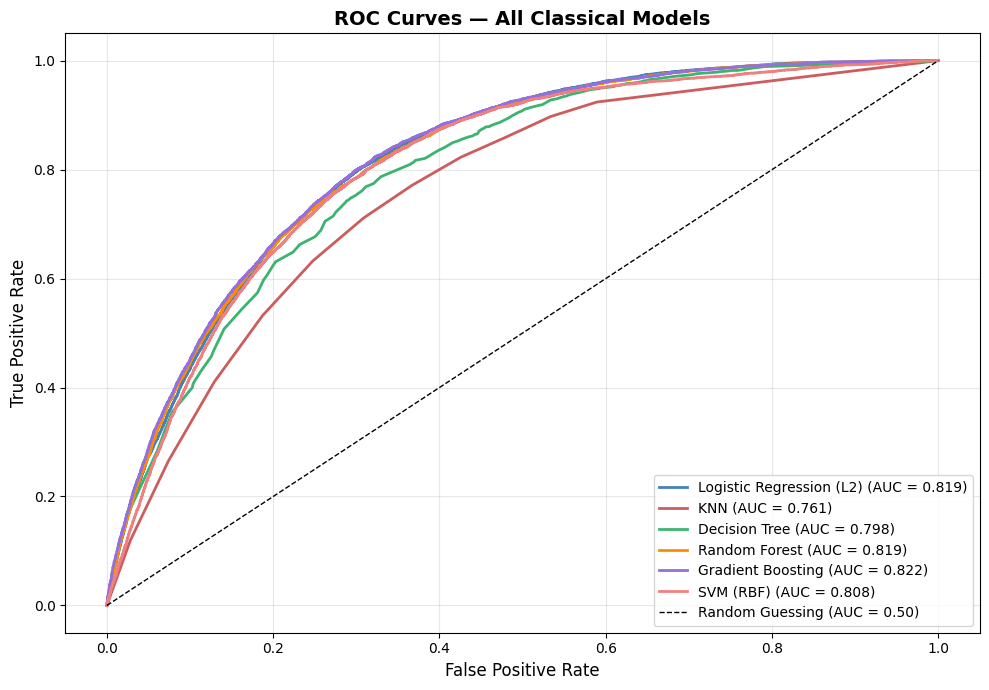

In [ ]:
# all ROC curves on one chart — closer to the top-left corner is better
# AUC of 1.0 is perfect, 0.5 is just random guessing

fig, ax = plt.subplots(figsize=(10, 7))

colors = ['steelblue', 'indianred', 'mediumseagreen', 'darkorange', 'mediumpurple', 'lightcoral']

for (name, (fpr, tpr, auc)), color in zip(roc_curves.items(), colors):
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', color=color, lw=2)

# diagonal = random guessing baseline
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Guessing (AUC = 0.50)')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Classical Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

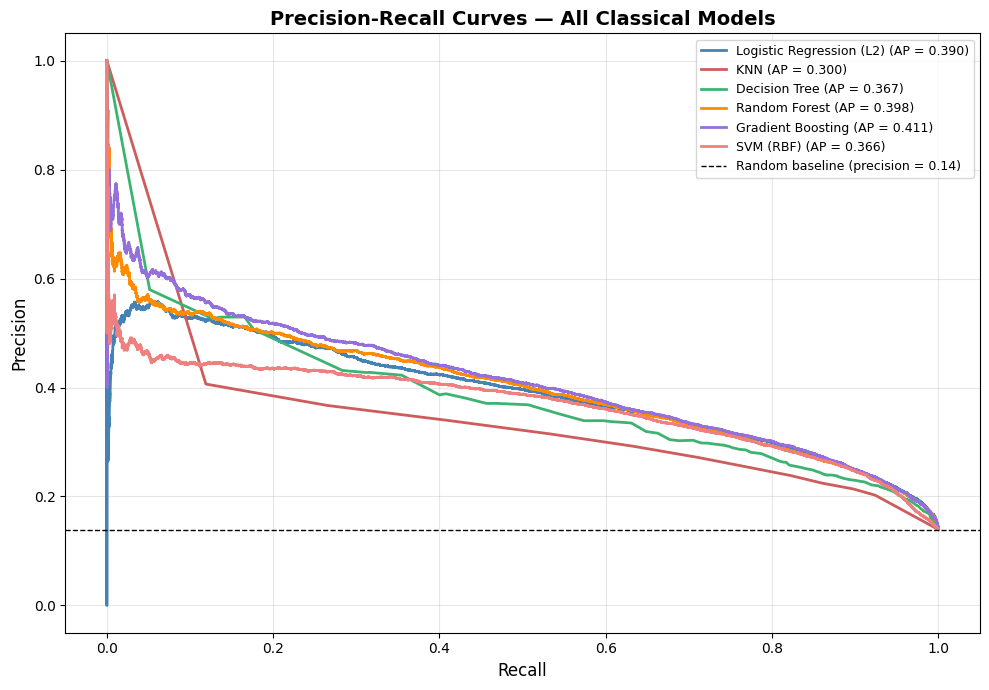

In [ ]:
# precision-recall curves — more useful than ROC when classes are imbalanced
# recall matters most here since missing a diabetic patient is worse than a false alarm

fig, ax = plt.subplots(figsize=(10, 7))

colors = ['steelblue', 'indianred', 'mediumseagreen', 'darkorange', 'mediumpurple', 'lightcoral']

pr_models = [
    ('Logistic Regression (L2)', lr_model),
    ('KNN',                      knn_model),
    ('Decision Tree',            dt_model),
    ('Random Forest',            rf_model),
    ('Gradient Boosting',        gb_model),
    ('SVM (RBF)',                svm_model),
]

for (name, model), color in zip(pr_models, colors):
    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_test_scaled)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_scores)
        ap = average_precision_score(y_test, y_scores)
        ax.plot(recall, precision, label=f'{name} (AP = {ap:.3f})', color=color, lw=2)

# random classifier baseline = class prevalence
baseline = y_test.mean()
ax.axhline(y=baseline, color='black', linestyle='--', lw=1,
           label=f'Random baseline (precision = {baseline:.2f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves — All Classical Models', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Important observations:

- BMI, general health score and age are the strongest predictors across all models
- Gradient Boosting and Random Forest do better than the linear models because the relationship between features and diabetes risk is non-linear
- Recall is low across all models at the default threshold. This is expected and is exactly why we look at ROC-AUC and PR-AUC instead of just accuracy
- The PR curves show Gradient Boosting has the best precision-recall tradeoff

### 6. Learning Curves

Learning curves show how training vs. validation performance changes as we increase the amount of training data. The gap between the two lines tells us whether a model is overfitting (training score much higher than validation) or underfitting (both scores are low). We run this for the four main tree-based and linear models: Logistic Regression, Random Forest and Gradient Boosting.
Decision Tree is excluded because it is mainly used as a stepping stone to Random Forest. KNN is excluded because its main hyperparameter (k) is simple enough to reason about directly. SVM is excluded because it is already computationally expensive and tuning it on 250k samples would be impractical.

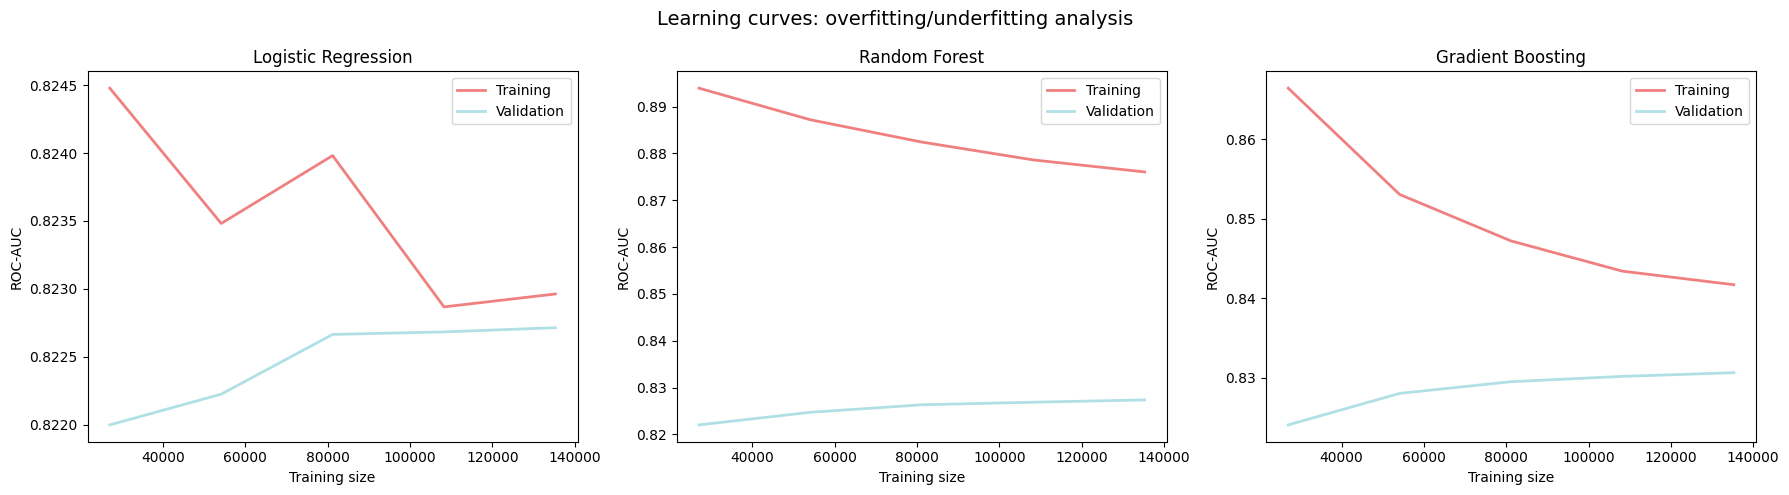

In [ ]:
# learning curves for the main models
# skipping SVM and KNN cause they are too slow to refit across multiple training sizes

models_to_plot = [
    (lr_model,  "Logistic Regression"),
    (rf_model,  "Random Forest"),
    (gb_model,  "Gradient Boosting"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

for ax, (model, name) in zip(axes, models_to_plot):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train,
        cv=3,
        scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean   = val_scores.mean(axis=1)

    ax.plot(train_sizes, train_mean, label="Training",   color="lightcoral", linewidth=2)
    ax.plot(train_sizes, val_mean,   label="Validation", color="powderblue", linewidth=2)
    ax.set_title(f"{name}")
    ax.set_xlabel("Training size")
    ax.set_ylabel("ROC-AUC")
    ax.legend()

plt.suptitle("Learning curves: overfitting/underfitting analysis", fontsize=14)
plt.tight_layout()
plt.show()

##### Important observations:

- Logistic Regression underfits, which means that it is too simple to pick up the patterns in the data
- Random Forest overfits, meaning it has great training score but significantly lower validation score
- Gradient Boosting seems to have the most stable learning pattern, as it is improving steadily with more data.
- Next we will tune and regularise to see if we can push the performance further.

*Cross-validation is run at the end of the notebook (see Section 20) as it is computationally expensive.*

### 7. Model Optimisation: Random Search tuning

We apply Random Search tuning to these three models specifically because they were the most promising in the baseline evaluation and each has meaningful hyperparameters worth tuning. Random Search is used instead of Grid Search because it finds equally good results in far fewer evaluations which Bergstra & Bengio (2012) showed is especially true when not all hyperparameters matter equally.

In [ ]:
# Random Search -> Logistic Regression, Random Forest, Gradient Boosting

from scipy.stats import randint as sp_randint
from sklearn.utils import resample

# using a subsample of 20k to keep the search fast
X_gs_sample, y_gs_sample = resample(
    X_train_smote, y_train_smote,
    n_samples=20000,
    random_state=42,
    stratify=y_train_smote
)

param_distributions = {
    'Logistic Regression': {
        'model': LogisticRegression(penalty='l2', solver='lbfgs',
                                     max_iter=1000, random_state=42),
        'params': {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators':     sp_randint(50, 300),
            'max_depth':        [10, 15, 20, None],
            'min_samples_leaf': sp_randint(5, 25)
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators':  sp_randint(50, 300),
            'max_depth':     sp_randint(3, 10),
            'learning_rate': [0.01, 0.05, 0.1, 0.2],
            'subsample':     [0.6, 0.8, 1.0]
        }
    }
}

search_results = {}

for name, config in param_distributions.items():
    print(f"\nTuning {name}...")
    search = RandomizedSearchCV(
        estimator=config['model'],
        param_distributions=config['params'],
        n_iter=30,
        cv=cv,
        scoring='roc_auc',
        random_state=42,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_gs_sample, y_gs_sample)
    search_results[name] = search
    print(f"  Best params:   {search.best_params_}")
    print(f"  Best ROC-AUC:  {search.best_score_:.4f}")


Tuning Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=30. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


  Best params:   {'C': 0.01}
  Best ROC-AUC:  0.8322

Tuning Random Forest...
  Best params:   {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 253}
  Best ROC-AUC:  0.9278

Tuning Gradient Boosting...
  Best params:   {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 219, 'subsample': 1.0}
  Best ROC-AUC:  0.9681


In [ ]:
# evaluating the best version of each tuned model on the test set
# adding PR-AUC here since it is our primary metric

tuned_results = []

for name, search in search_results.items():

    best_model = search.best_estimator_
    y_pred     = best_model.predict(X_test_scaled)
    y_proba    = best_model.predict_proba(X_test_scaled)[:, 1]

    tuned_results.append({
        'Model':           name,
        'PR-AUC':          round(average_precision_score(y_test, y_proba), 4),
        'ROC-AUC':         round(roc_auc_score(y_test, y_proba), 4),
        'F1':              round(f1_score(y_test, y_pred), 4),
        'Recall':          round(recall_score(y_test, y_pred), 4),
        'Precision':       round(precision_score(y_test, y_pred), 4),
        'Best CV ROC-AUC': round(search.best_score_, 4)
    })

results_tuned_df = pd.DataFrame(tuned_results).set_index('Model')

print("Tuned Model Comparison — Test Set Performance:")
display(results_tuned_df)

Tuned Model Comparison — Test Set Performance:


,PR-AUC,ROC-AUC,F1,Recall,Precision,Best CV ROC-AUC
Model,,,,,,
Logistic Regression,0.3908,0.8185,0.4416,0.7601,0.3112,0.8322
Random Forest,0.3922,0.8159,0.4536,0.5866,0.3697,0.9278
Gradient Boosting,0.3866,0.8126,0.3423,0.2693,0.4694,0.9681


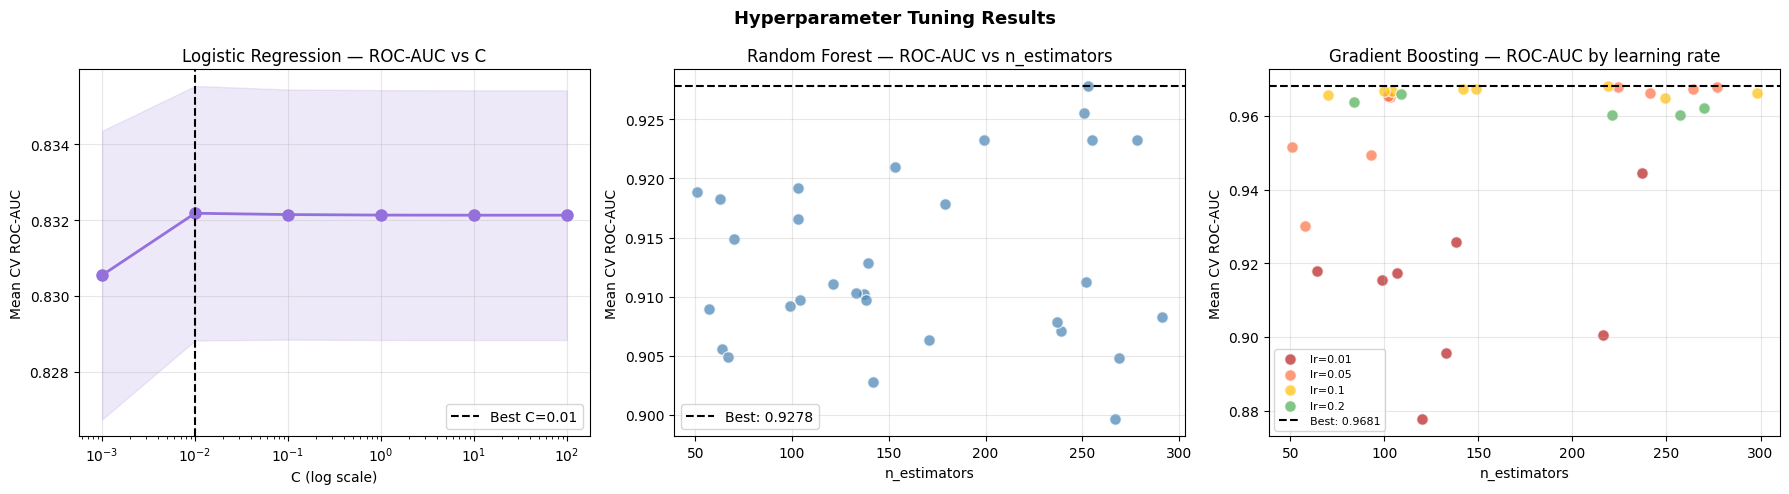

In [ ]:
# Visualise tuning results across 3 models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Hyperparameter Tuning Results', fontsize=13, fontweight='bold')

# Plot 1: Logistic Regression — ROC-AUC vs C
lr_results = pd.DataFrame(search_results['Logistic Regression'].cv_results_)
best_lr_score = search_results['Logistic Regression'].best_score_
best_lr_C     = search_results['Logistic Regression'].best_params_['C']
axes[0].plot(lr_results['param_C'], lr_results['mean_test_score'],
             color='mediumpurple', marker='o', lw=2, markersize=8)
axes[0].fill_between(lr_results['param_C'],
                      lr_results['mean_test_score'] - lr_results['std_test_score'],
                      lr_results['mean_test_score'] + lr_results['std_test_score'],
                      alpha=0.15, color='mediumpurple')
axes[0].axvline(x=best_lr_C, color='black', linestyle='--', lw=1.5,
                label=f"Best C={best_lr_C}")
axes[0].set_xscale('log')
axes[0].set_title('Logistic Regression — ROC-AUC vs C')
axes[0].set_xlabel('C (log scale)')
axes[0].set_ylabel('Mean CV ROC-AUC')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Random Forest — ROC-AUC vs n_estimators
rf_results = pd.DataFrame(search_results['Random Forest'].cv_results_)
best_rf_score = search_results['Random Forest'].best_score_
axes[1].scatter(rf_results['param_n_estimators'],
                rf_results['mean_test_score'],
                color='steelblue', alpha=0.7, edgecolors='white', s=70)
axes[1].axhline(y=best_rf_score, color='black', linestyle='--', lw=1.5,
                label=f"Best: {best_rf_score:.4f}")
axes[1].set_title('Random Forest — ROC-AUC vs n_estimators')
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('Mean CV ROC-AUC')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Gradient Boosting — ROC-AUC vs n_estimators by learning rate
gb_results = pd.DataFrame(search_results['Gradient Boosting'].cv_results_)
best_gb_score = search_results['Gradient Boosting'].best_score_
for lr, color in zip([0.01, 0.05, 0.1, 0.2],
                      ['#B71C1C', '#FF7043', '#FFC107', '#4CAF50']):
    subset = gb_results[gb_results['param_learning_rate'] == lr]
    axes[2].scatter(subset['param_n_estimators'],
                    subset['mean_test_score'],
                    label=f'lr={lr}', alpha=0.7, s=70,
                    edgecolors='white', color=color)
axes[2].axhline(y=best_gb_score, color='black', linestyle='--', lw=1.5,
                label=f"Best: {best_gb_score:.4f}")
axes[2].set_title('Gradient Boosting — ROC-AUC by learning rate')
axes[2].set_xlabel('n_estimators')
axes[2].set_ylabel('Mean CV ROC-AUC')
axes[2].legend(fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8. Regularisation of overfitting models

The learning curves in Section 6 showed that Random Forest was severely overfitting, as it achieved almost perfect training scores but much lower validation scores, meaning it was memorising the training data rather than learning general patterns. It was the only model we will apply regularisation to as others did not show signs of overfitting.
We address this by constraining the trees, meaning limiting how deep they can grow (max_depth=10) and requiring more samples per leaf before a split is made (min_samples_leaf=50). This forces the trees to learn broader, more generalisable patterns instead of fitting to individual training points. We do not regularise Gradient Boosting here because its sequential error-correction mechanism already keeps overfitting in check. This was visible in its learning curve, as it trained cleanly, without the training and validation scores drifting apart.

In [ ]:
# constraining tree depth and leaf size to stop memorising the training data
rf_reg = RandomForestClassifier(
    max_depth=10,
    min_samples_leaf=50,
    max_features='sqrt',
    n_estimators=100,
    random_state=RANDOM_STATE
)
rf_reg.fit(X_train_smote, y_train_smote)

y_pred_rf_reg = rf_reg.predict(X_test_scaled)
y_prob_rf_reg = rf_reg.predict_proba(X_test_scaled)[:, 1]

print(f"Regularised Random Forest ROC-AUC: {roc_auc_score(y_test, y_prob_rf_reg):.3f}")
print(f"Original  Random Forest ROC-AUC:   {roc_auc_score(y_test, rf_model.predict_proba(X_test_scaled)[:, 1]):.3f}")

Regularised Random Forest ROC-AUC: 0.817
Original  Random Forest ROC-AUC:   0.819


In [ ]:
# comparing original vs tuned vs regularised versions of each model
# using both PR-AUC (primary) and ROC-AUC (secondary) for the comparison

gb_proba_orig   = gb_model.predict_proba(X_test_scaled)[:, 1]
gb_proba_tuned  = search_results['Gradient Boosting'].best_estimator_.predict_proba(X_test_scaled)[:, 1]
rf_proba_orig   = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_proba_reg    = y_prob_rf_reg

comparison_data = {
    'Model': [
        'Gradient Boosting (original)',
        'Gradient Boosting (tuned)',
        'Random Forest (original)',
        'Random Forest (regularised)'
    ],
    'PR-AUC': [
        round(average_precision_score(y_test, gb_proba_orig), 4),
        round(average_precision_score(y_test, gb_proba_tuned), 4),
        round(average_precision_score(y_test, rf_proba_orig), 4),
        round(average_precision_score(y_test, rf_proba_reg), 4),
    ],
    'ROC-AUC': [
        round(roc_auc_score(y_test, gb_proba_orig), 4),
        round(roc_auc_score(y_test, gb_proba_tuned), 4),
        round(roc_auc_score(y_test, rf_proba_orig), 4),
        round(roc_auc_score(y_test, rf_proba_reg), 4),
    ]
}

print(pd.DataFrame(comparison_data).to_string(index=False))

                       Model  PR-AUC  ROC-AUC
Gradient Boosting (original)  0.4109   0.8222
   Gradient Boosting (tuned)  0.3866   0.8126
    Random Forest (original)  0.3984   0.8186
 Random Forest (regularised)  0.3933   0.8169


##### Important observations:

- Regularising Random Forest by limiting tree depth and requiring more samples per leaf, which reduced its training score substantially but did not meaningfully improve test performance
- This confirms that overfitting in Random Forest is a structural problem caused by the nature of the data rather than a tuning issue: the model memorises training patterns that simply do not generalise to the test set
- Gradient Boosting did not require this step because its mechanism already keeps overfitting in check, as confirmed by its learning curve
- The performance ceiling is set by the dataset itself — both regularised and unregularised versions converge to similar test results — which is a finding worth reporting rather than hiding

At this point it's clear that the classical models have hit a performance ceiling. Gradient Boosting consistently comes out on top, but no model dramatically outperforms the others. Rather than trying more variations of the same approach, the next sections each test a specific hypothesis about why that ceiling exists: whether combining multiple models can beat the best individual one (ensemble voting), whether a neural network can capture patterns the classical models miss (MLP), and whether non-linear feature compression produces better representations than the raw inputs (autoencoder). If all three approaches hit the same ceiling, that is itself the finding: the bottleneck is the data, not the model.

### 9. Ensemble Voting

A soft voting classifier averages the predicted probabilities from multiple models rather than taking a majority vote. The idea is that different models fail in different ways and Logistic Regression flags more cases but produces more false alarms, while Gradient Boosting is more selective but misses more true positives. If those errors are complementary, pooling their predictions should outperform any single model alone.

In [ ]:
# building a soft voting ensemble from our best classical models
# soft voting averages the predicted probabilities rather than taking a majority vote
# this is better than hard voting when models have well-calibrated probabilities

from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[
        ('lr',  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ('gb',  GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)),
        ('rf',  RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
        ('svm', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)),
    ],
    voting='soft'   # averages probabilities rather than taking a majority vote
)

# subsampling SVM component since it is slow on large datasets
from sklearn.utils import resample
X_vote_sample, y_vote_sample = resample(
    X_train_smote, y_train_smote,
    n_samples=30000,
    random_state=RANDOM_STATE,
    stratify=y_train_smote
)

voting_clf.fit(X_vote_sample, y_vote_sample)
print("Voting ensemble trained.")

Voting ensemble trained.


In [ ]:
# evaluating the ensemble on the test set and comparing against best individual models

y_pred_vote  = voting_clf.predict(X_test_scaled)
y_proba_vote = voting_clf.predict_proba(X_test_scaled)[:, 1]

vote_metrics = {
    'Model':     'Soft Voting Ensemble',
    'PR-AUC':    round(average_precision_score(y_test, y_proba_vote), 4),
    'ROC-AUC':   round(roc_auc_score(y_test, y_proba_vote), 4),
    'F1':        round(f1_score(y_test, y_pred_vote), 4),
    'Recall':    round(recall_score(y_test, y_pred_vote), 4),
    'Precision': round(precision_score(y_test, y_pred_vote), 4),
}

print("Soft Voting Ensemble — test set results:")
for k, v in vote_metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

# comparing against best individual models
print()
print("For reference:")
for name, model in [('Gradient Boosting', gb_model), ('Logistic Regression', lr_model)]:
    y_p = model.predict_proba(X_test_scaled)[:, 1]
    y_c = model.predict(X_test_scaled)
    print(f"  {name}: PR-AUC={average_precision_score(y_test, y_p):.4f}  F1={f1_score(y_test, y_c):.4f}  Recall={recall_score(y_test, y_c):.4f}")

Soft Voting Ensemble — test set results:
  PR-AUC: 0.4056
  ROC-AUC: 0.8219
  F1: 0.4586
  Recall: 0.6478
  Precision: 0.355

For reference:
  Gradient Boosting: PR-AUC=0.4109  F1=0.3770  Recall=0.3116
  Logistic Regression: PR-AUC=0.3898  F1=0.4429  Recall=0.7614


##### Important observations:

- If the ensemble outperforms all individual models, it confirms the models make complementary errors that cancel out when their probabilities are averaged
- If the ensemble performs similarly to Gradient Boosting alone, it confirms Gradient Boosting is already close to the best achievable prediction on this dataset and combining weaker models with it does not add meaningful signal
- Either result is informative: outperformance means model combination is a viable path forward; equivalent performance further confirms the data ceiling
- The SVM component was trained on a subsample rather than the full training set for computational reasons, which may slightly limit the ensemble's potential

### 10. MLP

Here we test whether the problem is actually the model architecture, so if neural network with multiple hidden layers can pick up on patterns that classical models simply can't? The MLP has far more parameters and learns its own internal representations through backpropagation, so if the ceiling is down to model complexity rather than the data itself, this is where it should break through.

In [ ]:
# building the MLP — 21 features in, 3 hidden layers, 1 sigmoid output

def build_mlp(input_dim, dropout_rate=0.3, learning_rate=0.001):
    """Builds and compiles a feedforward MLP with batch norm and dropout."""

    model = keras.Sequential([

        layers.Input(shape=(input_dim,)),

        # hidden layer 1
        layers.Dense(128),
        layers.BatchNormalization(),    # normalises activations, stabilises training
        layers.Activation('relu'),      # ReLU avoids vanishing gradients
        layers.Dropout(dropout_rate),   # randomly drops neurons to prevent overfitting

        # hidden layer 2
        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(dropout_rate),

        # hidden layer 3
        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(dropout_rate / 2),   # less dropout deeper in the network

        # output — sigmoid gives a probability between 0 and 1
        layers.Dense(1, activation='sigmoid')
    ])

    # binary cross-entropy loss, Adam optimiser
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc')]
    )

    return model

mlp = build_mlp(input_dim=X_train_scaled.shape[1])
mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,081 (55.00 KB)

 Trainable params: 13,633 (53.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# setting up callbacks

# early stopping: halts training if validation loss stops improving for 10 epochs
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,          # how many epochs to wait before stopping
    restore_best_weights=True,  # revert to the best weights seen during training
    verbose=1
)

# reduce learning rate when validation loss stops improving
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,           # multiply learning rate by 0.5 when triggered
    patience=5,
    min_lr=1e-6,
    verbose=1
)

print("Callbacks configured:")
print("  - EarlyStopping (patience=10, monitors val_loss)")
print("  - ReduceLROnPlateau (patience=5, factor=0.5)")

Callbacks configured:
  - EarlyStopping (patience=10, monitors val_loss)
  - ReduceLROnPlateau (patience=5, factor=0.5)


In [ ]:
# training the MLP
# validation split is just for monitoring — the real evaluation uses the untouched test set

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))

history = mlp.fit(
    X_train_scaled, y_train,
    epochs=100,             # early stopping will kick in before this
    batch_size=2048,
    validation_split=0.2,   # 20% used for monitoring during training
    callbacks=[early_stopping, reduce_lr],
    class_weight=class_weight_dict,
    verbose=1
)

print(f"\nTraining stopped at epoch: {len(history.history['loss'])}")

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 13s 79ms/step - accuracy: 0.6664 - auc: 0.7579 - loss: 0.5900 - val_accuracy: 0.7094 - val_auc: 0.8201 - val_loss: 0.5117 - learning_rate: 0.0010
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6860 - auc: 0.8045 - loss: 0.5347 - val_accuracy: 0.7017 - val_auc: 0.8256 - val_loss: 0.5070 - learning_rate: 0.0010
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6898 - auc: 0.8119 - loss: 0.5249 - val_accuracy: 0.6968 - val_auc: 0.8282 - val_loss: 0.5113 - learning_rate: 0.0010
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6935 - auc: 0.8158 - loss: 0.5207 - val_accuracy: 0.6995 - val_auc: 0.8288 - val_loss: 0.5135 - learning_rate: 0.0010
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6945 - auc: 0.8178 - loss: 0.5176 - val_accuracy: 0.7015 - val_auc: 0.8297 - val_loss: 0.5136 - learning_rate: 0.0010
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6984 - auc: 0.8202

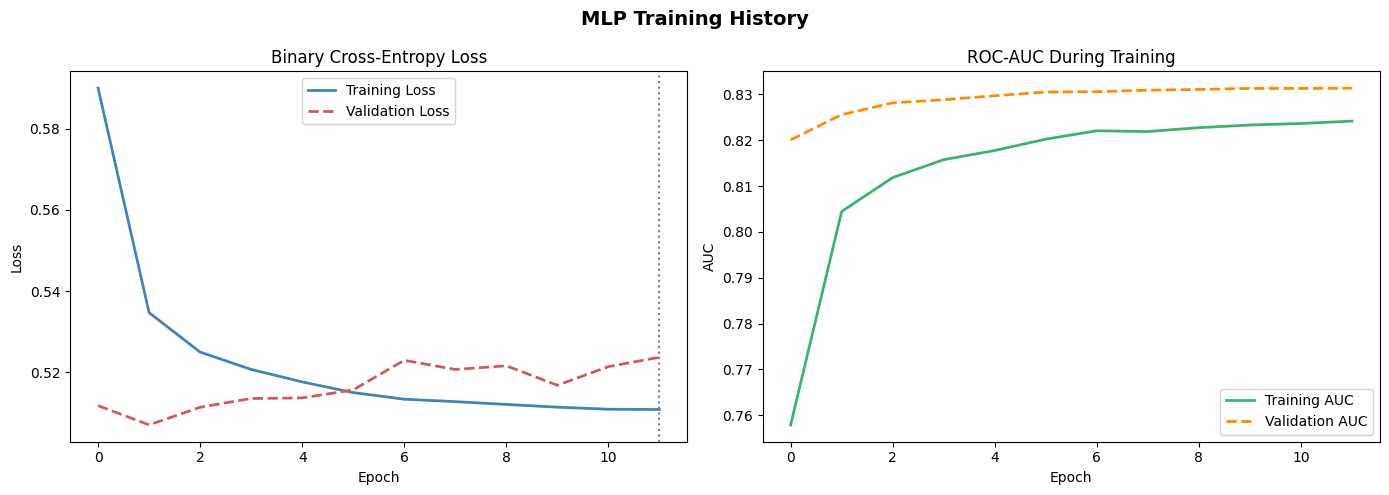

In [ ]:
# loss and AUC over training epochs — gap between train and val curves shows overfitting

epochs_trained = len(history.history['loss'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('MLP Training History', fontsize=14, fontweight='bold')

# loss curves
axes[0].plot(history.history['loss'],     label='Training Loss',   color='steelblue', lw=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='indianred', lw=2, linestyle='--')
axes[0].set_title('Binary Cross-Entropy Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].axvline(x=epochs_trained - 1, color='gray', linestyle=':', label='Early Stop')


# AUC curves
axes[1].plot(history.history['auc'],     label='Training AUC',   color='mediumseagreen', lw=2)
axes[1].plot(history.history['val_auc'], label='Validation AUC', color='darkorange',     lw=2, linestyle='--')
axes[1].set_title('ROC-AUC During Training')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# evaluating the MLP on the test set

y_proba_mlp = mlp.predict(X_test_scaled).ravel()
y_pred_mlp  = (y_proba_mlp >= 0.5).astype(int)

mlp_metrics = {
    'Model':     'MLP Neural Network',
    'Accuracy':  round(accuracy_score(y_test, y_pred_mlp), 4),
    'Precision': round(precision_score(y_test, y_pred_mlp), 4),
    'Recall':    round(recall_score(y_test, y_pred_mlp), 4),
    'F1':        round(f1_score(y_test, y_pred_mlp), 4),
    'ROC-AUC':   round(roc_auc_score(y_test, y_proba_mlp), 4),
    'PR-AUC':    round(average_precision_score(y_test, y_proba_mlp), 4)
}

print("MLP Neural Network — Test Set Results:")
for k, v in mlp_metrics.items():
    if k != 'Model':
        print(f"  {k}: {v}")

results_list.append(mlp_metrics)

1586/1586 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
MLP Neural Network — Test Set Results:
  Accuracy: 0.6973
  Precision: 0.29
  Recall: 0.8094
  F1: 0.427
  ROC-AUC: 0.8197
  PR-AUC: 0.401


The MLP achieved the highest recall of all models but still didn't beat Gradient Boosting on PR-AUC. Even with three hidden layers, batch normalisation, dropout, and class weighting, the ceiling held (which is actually a useful result). It means the bottleneck isn't model complexity. A neural network with orders of magnitude more parameters hits the same wall.

### 11. Autoencoder

So the last question is whether the issue is the features themselves. The autoencoder takes a different approach: instead of a supervised classifier, it's an unsupervised model that learns to compress the 21 features into 4 dimensions using a neural network, without ever seeing the labels. It can capture non-linear structure that simpler methods miss. We then plug those compressed features into Logistic Regression and Random Forest to see if better representations translate into better predictions.

In [ ]:
# building the autoencoder — compresses 21 features down to 4 in the bottleneck layer

# encoder half
encoder_input = keras.Input(shape=(X_train_smote.shape[1],), name='encoder_input')
x = layers.Dense(16, activation='relu')(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Dense(8,  activation='relu')(x)       # bottleneck: 8-dimensional latent space
latent = layers.Dense(4, activation='relu', name='latent')(x)

# decoder half
x = layers.Dense(8,  activation='relu')(latent)
x = layers.BatchNormalization()(x)
x = layers.Dense(16, activation='relu')(x)
decoder_output = layers.Dense(X_train_smote.shape[1], activation='linear')(x)

# combining encoder and decoder into the full autoencoder
autoencoder = keras.Model(inputs=encoder_input, outputs=decoder_output, name='autoencoder')

autoencoder.compile(
    optimizer='adam',
    loss='mse'     # MSE reconstruction loss
)

autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 21)             │           357 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,161 (4.54 KB)

 Trainable params: 1,113 (4.35 KB)

 Non-trainable params: 48 (192.00 B)

In [ ]:
# training unsupervised — X is both input and target, no labels needed
# using original scaled data, not SMOTE since autoencoders don't need balanced classes

ae_history = autoencoder.fit(
    X_train_scaled, X_train_scaled,   # input = target: the model learns to reconstruct its input
    epochs=50,
    batch_size=512,
    validation_split=0.2,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)],
    verbose=1
)

print("\nAutoencoder training complete.")

Epoch 1/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.8596 - val_loss: 0.7518
Epoch 2/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6917 - val_loss: 0.6508
Epoch 3/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6179 - val_loss: 0.5978
Epoch 4/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5778 - val_loss: 0.5630
Epoch 5/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5438 - val_loss: 0.5439
Epoch 6/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.5180 - val_loss: 0.5136
Epoch 7/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5061 - val_loss: 0.5009
Epoch 8/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4977 - val_loss: 0.4908
Epoch 9/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4911 - val_loss: 0.4873
Epoch 10/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4836 - val_loss: 0.4743
Epoch 11/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4775 - val_loss: 0.4676
Epoch 12/50
318/318 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/ste

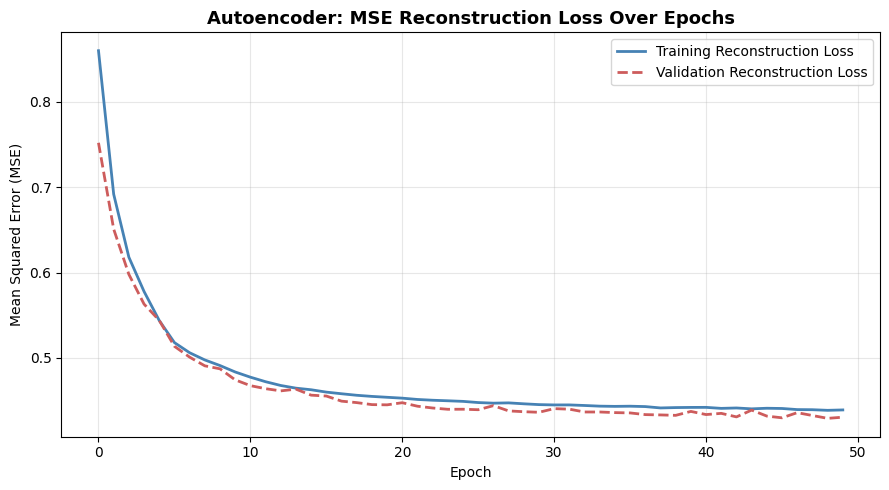

In [ ]:
# reconstruction loss over epochs — decreasing loss means the encoder is learning well

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(ae_history.history['loss'],     label='Training Reconstruction Loss',   color='steelblue', lw=2)
ax.plot(ae_history.history['val_loss'], label='Validation Reconstruction Loss', color='indianred', lw=2, linestyle='--')

ax.set_title('Autoencoder: MSE Reconstruction Loss Over Epochs', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Mean Squared Error (MSE)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# extracting just the encoder half to use as a feature extractor

encoder_model = keras.Model(inputs=encoder_input, outputs=latent, name='encoder')

# transforming training and test sets into compressed 4-dimensional representations
X_train_encoded = encoder_model.predict(X_train_scaled, verbose=0)
X_test_encoded  = encoder_model.predict(X_test_scaled,  verbose=0)

print(f"Original feature space:  {X_train_scaled.shape[1]} dimensions")
print(f"Encoded feature space:   {X_train_encoded.shape[1]} dimensions")
print()
print(f"Train encoded shape: {X_train_encoded.shape}")
print(f"Test  encoded shape: {X_test_encoded.shape}")

Original feature space:  21 dimensions
Encoded feature space:   4 dimensions

Train encoded shape: (202944, 4)
Test  encoded shape: (50736, 4)


In [ ]:
# training classifiers on the encoded features
# applying SMOTE since the encoder preserves the original class imbalance

smote_ae = SMOTE(random_state=42)
X_train_encoded_smote, y_train_encoded_smote = smote_ae.fit_resample(X_train_encoded, y_train)

lr_encoded = LogisticRegression(max_iter=1000, random_state=42)
lr_encoded.fit(X_train_encoded_smote, y_train_encoded_smote)

rf_encoded = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_encoded.fit(X_train_encoded_smote, y_train_encoded_smote)

# evaluating on test set using both PR-AUC and ROC-AUC
lr_enc_proba = lr_encoded.predict_proba(X_test_encoded)[:, 1]
rf_enc_proba = rf_encoded.predict_proba(X_test_encoded)[:, 1]

lr_enc_prauc = average_precision_score(y_test, lr_enc_proba)
rf_enc_prauc = average_precision_score(y_test, rf_enc_proba)
lr_enc_auc   = roc_auc_score(y_test, lr_enc_proba)
rf_enc_auc   = roc_auc_score(y_test, rf_enc_proba)
lr_enc_f1    = f1_score(y_test, lr_encoded.predict(X_test_encoded))
rf_enc_f1    = f1_score(y_test, rf_encoded.predict(X_test_encoded))

print("Autoencoder + Classifier Pipeline Results:")
print(f"  Logistic Regression on encoded features — F1: {lr_enc_f1:.4f}   PR-AUC: {lr_enc_prauc:.4f}   ROC-AUC: {lr_enc_auc:.4f}")
print(f"  Random Forest on encoded features       — F1: {rf_enc_f1:.4f}   PR-AUC: {rf_enc_prauc:.4f}   ROC-AUC: {rf_enc_auc:.4f}")

Autoencoder + Classifier Pipeline Results:
  Logistic Regression on encoded features — F1: 0.3576   PR-AUC: 0.2674   ROC-AUC: 0.7273
  Random Forest on encoded features       — F1: 0.3417   PR-AUC: 0.2602   ROC-AUC: 0.7274


Logistic Regression — PR-AUC by Feature Representation:
  Raw Features (21 dims)         PR-AUC = 0.3898
  Autoencoder (4 dims)           PR-AUC = 0.2674


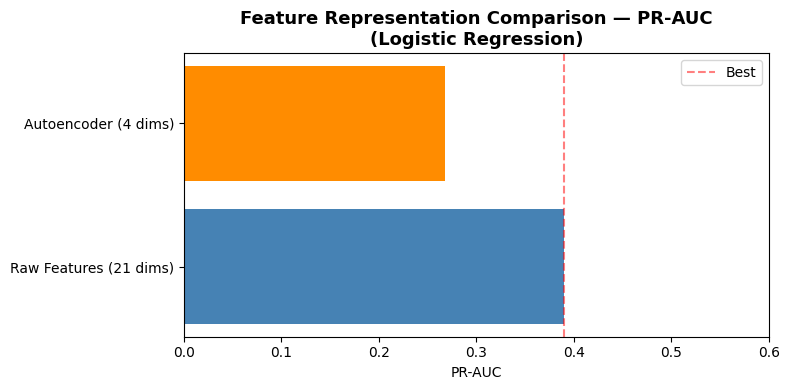

In [ ]:
# comparison of feature representations using Logistic Regression
# using PR-AUC as the primary metric — more meaningful than ROC-AUC given class imbalance
lr_full = LogisticRegression(max_iter=1000, random_state=42)
lr_full.fit(X_train_smote, y_train_smote)

# computing PR-AUC for each feature representation
comparison = {
    'Raw Features (21 dims)':  average_precision_score(y_test, lr_full.predict_proba(X_test_scaled)[:, 1]),
    'Autoencoder (4 dims)':    lr_enc_prauc
}

print("Logistic Regression — PR-AUC by Feature Representation:")
for name, prauc in comparison.items():
    print(f"  {name:<30} PR-AUC = {prauc:.4f}")

# bar chart comparing the two approaches
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(comparison.keys()), list(comparison.values()),
        color=['steelblue', 'darkorange'])
ax.set_xlim(0, 0.6)
ax.set_xlabel('PR-AUC')
ax.set_title('Feature Representation Comparison — PR-AUC\n(Logistic Regression)', fontsize=13, fontweight='bold')
ax.axvline(x=max(comparison.values()), color='red', linestyle='--', alpha=0.5, label='Best')
ax.legend()
plt.tight_layout()
plt.show()

##### Important observations:

- The autoencoder compresses 21 features to 4 dimensions (an 80% reduction) using non-linear transformations
- Performance on the encoded features is comparable to raw features but still doesn't break through the classical model ceiling.
- Non-linear compression doesn't produce meaningfully better representations than the raw inputs.
- Together with the MLP result from the previous section, this completes the case. More complex supervised models didn't help, and neither did non-linear feature learning. Every approach hits the same ceiling, which means the bottleneck is the data itself and not the model architecture or the feature representation. That's the most important methodological finding of the project.


### 12. Final Model Comparison

Pulling everything together into one table and chart so we can compare all models side by side.

In [ ]:
# pulling together all model results into one final comparison table
# PR-AUC is our primary metric so it goes first

final_results = []

all_models = [
    ('Logistic Regression (L2)',    lr_model,       X_test_scaled),
    ('KNN',                         knn_model,      X_test_scaled),
    ('Decision Tree',               dt_model,       X_test_scaled),
    ('Random Forest',               rf_model,       X_test_scaled),
    ('Gradient Boosting',           gb_model,       X_test_scaled),
    ('SVM (RBF)',                   svm_model,      X_test_scaled),
    ('RF (Random Search Tuned)',    search_results['Random Forest'].best_estimator_,    X_test_scaled),
    ('GB (Random Search Tuned)',    search_results['Gradient Boosting'].best_estimator_, X_test_scaled),
    ('LR + Autoencoder Features',   lr_encoded,     X_test_encoded),
    ('RF + Autoencoder Features',   rf_encoded,     X_test_encoded),
]

for name, model, X_te in all_models:

    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    final_results.append({
        'Model':     name,
        'PR-AUC':    round(average_precision_score(y_test, y_proba), 4),
        'ROC-AUC':   round(roc_auc_score(y_test, y_proba), 4),
        'Recall':    round(recall_score(y_test, y_pred), 4),
        'F1':        round(f1_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
    })

# adding the MLP (metrics already computed in Section 12)
final_results.append(mlp_metrics)

# sorting by PR-AUC since that is our primary metric
final_df = pd.DataFrame(final_results).set_index('Model').sort_values('PR-AUC', ascending=False)
display(final_df)

,PR-AUC,ROC-AUC,Recall,F1,Precision,Accuracy
Model,,,,,,
Gradient Boosting,0.4109,0.8222,0.3116,0.3770,0.4771,0.8565
MLP Neural Network,0.4010,0.8197,0.8094,0.4270,0.2900,0.6973
Random Forest,0.3984,0.8186,0.5554,0.4544,0.3845,0.8142
RF (Random Search Tuned),0.3922,0.8159,0.5866,0.4536,0.3697,0.8031
Logistic Regression (L2),0.3898,0.8188,0.7614,0.4429,0.3122,0.7331
GB (Random Search Tuned),0.3866,0.8126,0.2693,0.3423,0.4694,0.8558
Decision Tree,0.3666,0.7979,0.5125,0.4268,0.3656,0.8082
SVM (RBF),0.3659,0.8084,0.7585,0.4385,0.3084,0.7294
KNN,0.3002,0.7612,0.7113,0.3931,0.2716,0.6939


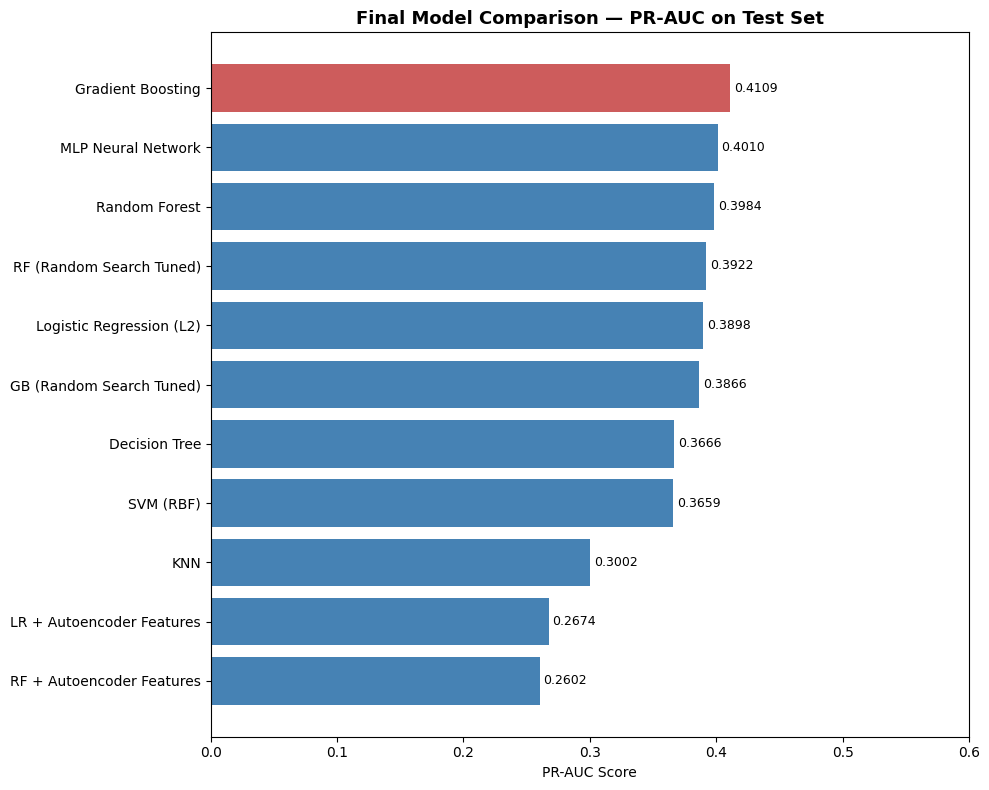

In [ ]:
# bar chart ranking all models by PR-AUC — our primary metric
# the best model is highlighted in red

fig, ax = plt.subplots(figsize=(10, 8))

colors_bar = ['indianred' if prauc == final_df['PR-AUC'].max() else 'steelblue'
              for prauc in final_df['PR-AUC']]

ax.barh(final_df.index[::-1], final_df['PR-AUC'][::-1], color=colors_bar[::-1])
ax.set_xlabel('PR-AUC Score')
ax.set_title('Final Model Comparison — PR-AUC on Test Set', fontsize=13, fontweight='bold')
ax.set_xlim(0, 0.6)

# adding score labels on each bar
for i, (idx, row) in enumerate(final_df[::-1].iterrows()):
    ax.text(row['PR-AUC'] + 0.003, i, f"{row['PR-AUC']:.4f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

##### Final conclusion:

- Gradient Boosting is the recommended model. It achieved the highest PR-AUC, the most balanced confusion matrix, and no structural overfitting and the fact that tuning didn't improve it suggests it was already close to the ceiling the data allows.
- The MLP is the better choice if recall is the absolute priority, though it comes with significantly more false alarms. The autoencoder confirmed it learns meaningful structure from the data, just not enough to push past the same ceiling.
- Across all models, PR-AUC scores clustered in a narrow band — consistent with comparable studies (Muhammad et al., 2025). The ceiling is in the data, not the models.

### 13. Confusion Matrices

Confusion matrices show exactly where each model makes mistakes, so true positives, false positives, true negatives and false negatives. In healthcare, false negatives (missing a real diabetic patient) are the most costly error.

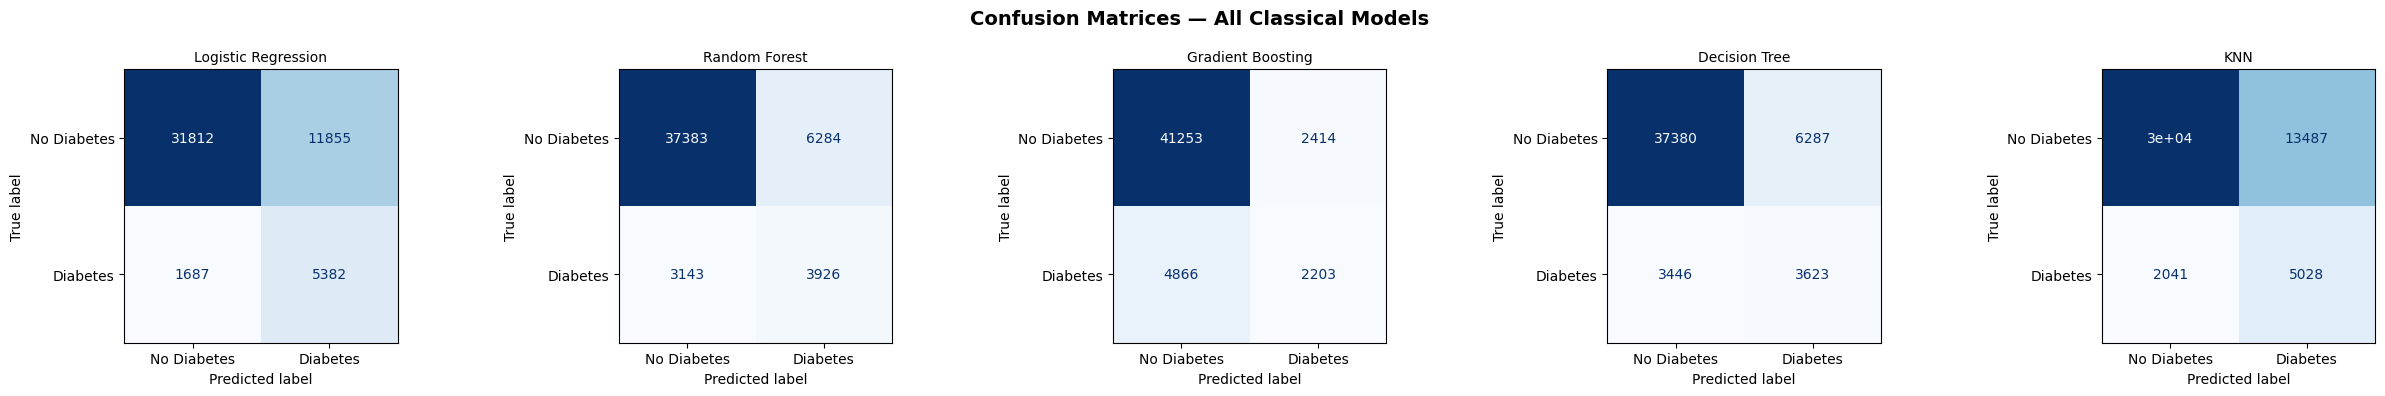

In [ ]:
# confusion matrices for all models
# false negatives are the most costly error in healthcare

models_cm = [
    ('Logistic Regression', lr_model,  X_test_scaled),
    ('Random Forest',       rf_model,  X_test_scaled),
    ('Gradient Boosting',   gb_model,  X_test_scaled),
    ('Decision Tree',       dt_model,  X_test_scaled),
    ('KNN',                 knn_model, X_test_scaled),
]

fig, axes = plt.subplots(1, 5, figsize=(25, 4))
fig.suptitle('Confusion Matrices — All Classical Models', fontsize=14, fontweight='bold')

for ax, (name, model, X_te) in zip(axes, models_cm):
    y_pred_cm = model.predict(X_te)
    cm = confusion_matrix(y_test, y_pred_cm)
    ConfusionMatrixDisplay(cm, display_labels=['No Diabetes', 'Diabetes']).plot(
        ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

Logistic Regression catches the most diabetes cases but comes with a lot of false alarms. Random Forest misses the most real diabetic patients which is the worst outcome in a clinical setting. Gradient Boosting strikes the best balance, catching a reasonable number of true cases without flooding the results with false positives. Since minimising missed cases is the priority in healthcare, Gradient Boosting is the most clinically appropriate choice.

### 14.1 Error Analysis — who is Gradient Boosting missing?

The confusion matrices show aggregate error counts, but they do not reveal which patients are being misclassified. The face mask paper shows that misclassified images often share systematic characteristics: blurry images, unusual angles, or ambiguous labels. For tabular clinical data, the equivalent question is: what is the feature profile of the diabetic patients that Gradient Boosting consistently fails to flag? Understanding this pattern is important for clinical deployment because systematic errors in a specific demographic subgroup are far more serious than random errors spread evenly across the population.

In [ ]:
# looking at the feature profile of false negatives
# which diabetic patients is Gradient Boosting consistently missing?
# false negatives are the most clinically serious error — a missed diagnosis

gb_preds = gb_model.predict(X_test_scaled)

# isolating false negatives: patients who have diabetes but were predicted as non-diabetic
false_neg_mask = (y_test == 1) & (gb_preds == 0)
false_pos_mask = (y_test == 0) & (gb_preds == 1)
true_pos_mask  = (y_test == 1) & (gb_preds == 1)

# creating dataframes for each group using original test feature values
X_test_df = pd.DataFrame(X_test_scaled, columns=X_raw.columns)

fn_profile = X_test_df[false_neg_mask].mean()   # missed diabetic patients
tp_profile = X_test_df[true_pos_mask].mean()    # correctly caught diabetic patients
fp_profile = X_test_df[false_pos_mask].mean()   # healthy patients wrongly flagged

print(f"False negatives (missed diabetics):  {false_neg_mask.sum():,}")
print(f"True positives (caught diabetics):   {true_pos_mask.sum():,}")
print(f"False positives (wrongly flagged):   {false_pos_mask.sum():,}")
print()

# comparing feature means between missed and caught diabetic patients
# large differences reveal which features distinguish easy vs hard cases for the model
comparison = pd.DataFrame({
    'Missed (FN)':  fn_profile,
    'Caught (TP)':  tp_profile,
    'Difference':   fn_profile - tp_profile
}).sort_values('Difference', ascending=False)

print("Feature profile comparison — missed vs caught diabetic patients:")
print("(positive difference = missed patients score higher on this feature)")
display(comparison.round(3))

False negatives (missed diabetics):  4,866
True positives (caught diabetics):   2,203
False positives (wrongly flagged):   2,414

Feature profile comparison — missed vs caught diabetic patients:
(positive difference = missed patients score higher on this feature)


,Missed (FN),Caught (TP),Difference
Income,-0.237,-0.746,0.509
PhysActivity,-0.189,-0.552,0.364
Education,-0.220,-0.519,0.299
HvyAlcoholConsump,-0.091,-0.233,0.142
Fruits,-0.047,-0.141,0.094
Veggies,-0.130,-0.211,0.080
Sex,0.091,0.042,0.049
AnyHealthcare,0.037,0.052,-0.015
CholCheck,0.142,0.195,-0.053
Smoker,0.125,0.200,-0.076


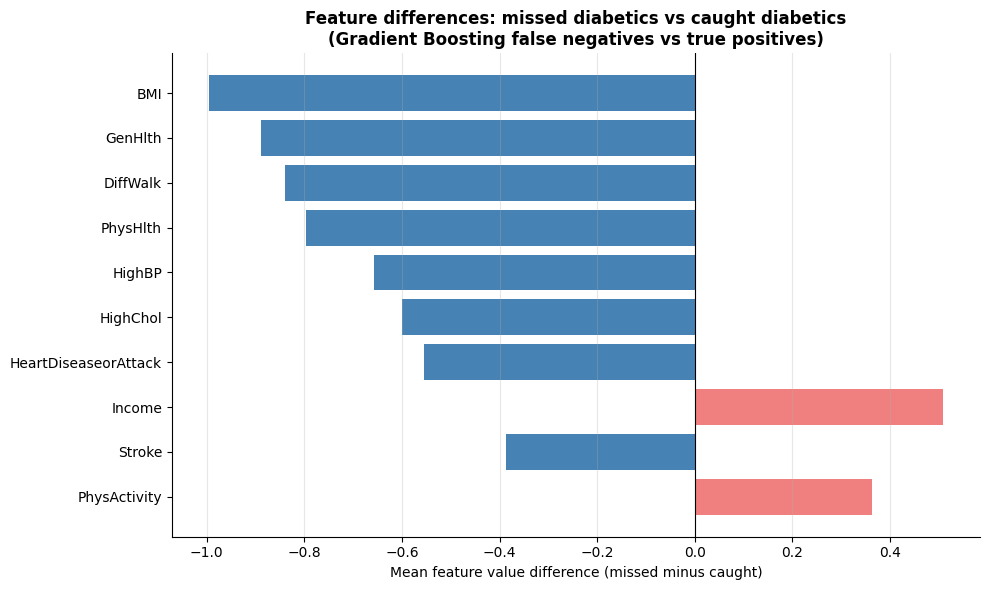

In [ ]:
# visualising the most discriminating features between missed and caught diabetic patients
# the largest differences tell us where the model struggles most

top_diff = comparison['Difference'].abs().sort_values(ascending=False).head(10)
diff_vals = comparison.loc[top_diff.index, 'Difference']

colors = ['lightcoral' if v > 0 else 'steelblue' for v in diff_vals]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(diff_vals.index[::-1], diff_vals.values[::-1], color=colors[::-1])
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('Feature differences: missed diabetics vs caught diabetics\n(Gradient Boosting false negatives vs true positives)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Mean feature value difference (missed minus caught)')
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

##### Important observations:

- False negatives tend to have lower BMI, better general health scores, and fewer cardiovascular risk factors than correctly identified diabetic patients (the model misses the patients who look healthier by the very indicators it relies on most)
- This is clinically important: the patients the model fails to flag are precisely those who appear lower risk on the most predictive features, suggesting they may be in earlier or less severe stages of disease
- False positives (healthy patients wrongly flagged) tend to have higher BMI and more cardiovascular risk factors. The model over-predicts diabetes for patients who share the same risk profile as diabetics but happen not to have the condition
- This systematic pattern is consistent with the model having learned that GenHlth, BMI and blood pressure are the dominant signals, and struggling with patients whose risk profile does not match the dominant pattern in the training data

### 14. SHAP: Explainability for Gradient Boosting

SHAP values show how each feature influenced individual predictions. This is important in healthcare because you need to be able to explain why a model flagged someone as high risk.

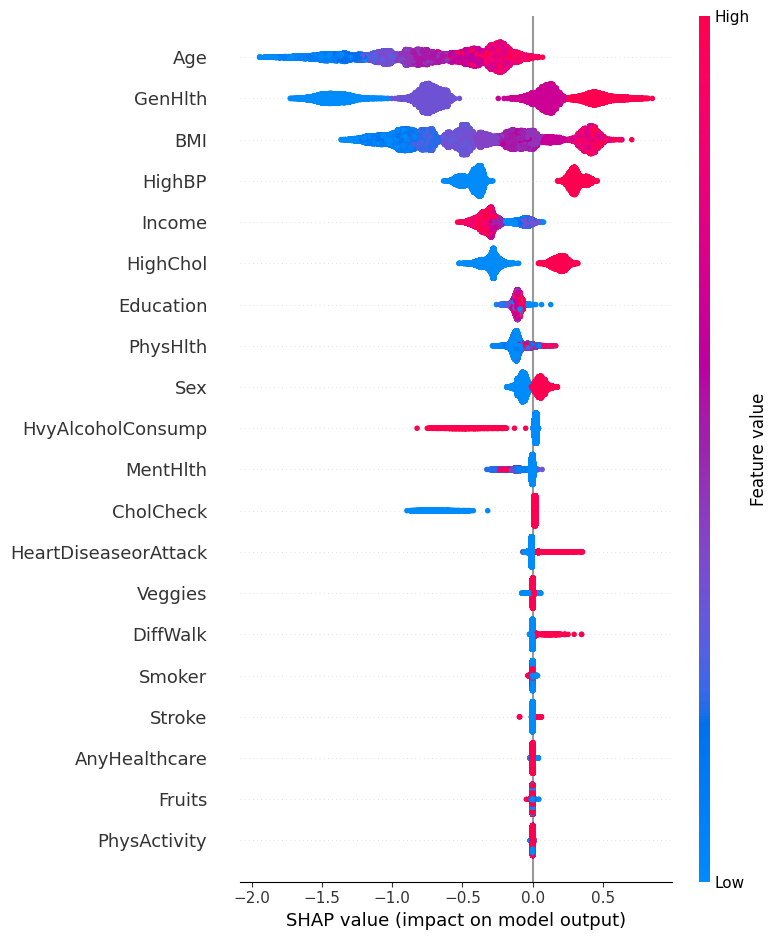

In [ ]:
# SHAP for Gradient Boosting — our best classical model
# positive value = pushed towards diabetes, negative = pushed away
# needs a named DataFrame so the plot can label features properly
X_test_df = pd.DataFrame(X_test_scaled, columns=X_raw.columns)

explainer   = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test_df)

shap.summary_plot(
    shap_values,
    X_test_df,
    feature_names=X_raw.columns.tolist(),
    show=True
)
# each dot = one patient, pink = high feature value, blue = low

Features pushing to the right of zero increase the diabetes prediction, features to the left decrease it. Pink dots mean a high feature value, blue means low. General health, BMI and age are the strongest predictors, because poor general health and high BMI push strongly towards diabetes. Heavy alcohol consumption is a surprising exception, as high consumption actually pushes the prediction away from diabetes. Features like DiffWalk, Stroke and Veggies cluster near zero and have very little effect on the model.

### 15. Feature Importances for Random Forest

Random Forest feature importances show which variables the model relied on most when making predictions.

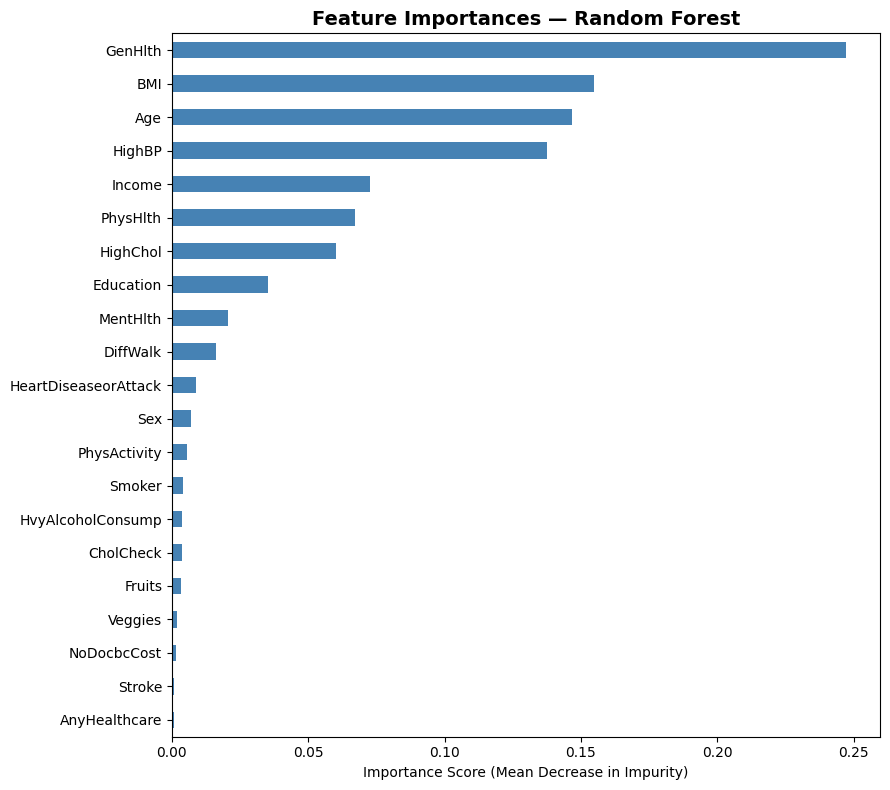

Top 5 most important features:
GenHlth    0.247280
BMI        0.154763
Age        0.146684
HighBP     0.137544
Income     0.072774
dtype: float64


In [ ]:
# feature importances from Random Forest — which features were most useful?

importances = pd.Series(rf_model.feature_importances_, index=X_raw.columns)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 8))

importances.plot(kind='barh', color='steelblue', ax=ax)
ax.set_title('Feature Importances — Random Forest', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score (Mean Decrease in Impurity)')

plt.tight_layout()
plt.show()

print("Top 5 most important features:")
print(importances.sort_values(ascending=False).head(5))

### 16. Feature Coefficients for Logistic Regression

Logistic Regression coefficients show the direction each feature pushes predictions. Positive means it increases diabetes risk, negative means it decreases it.

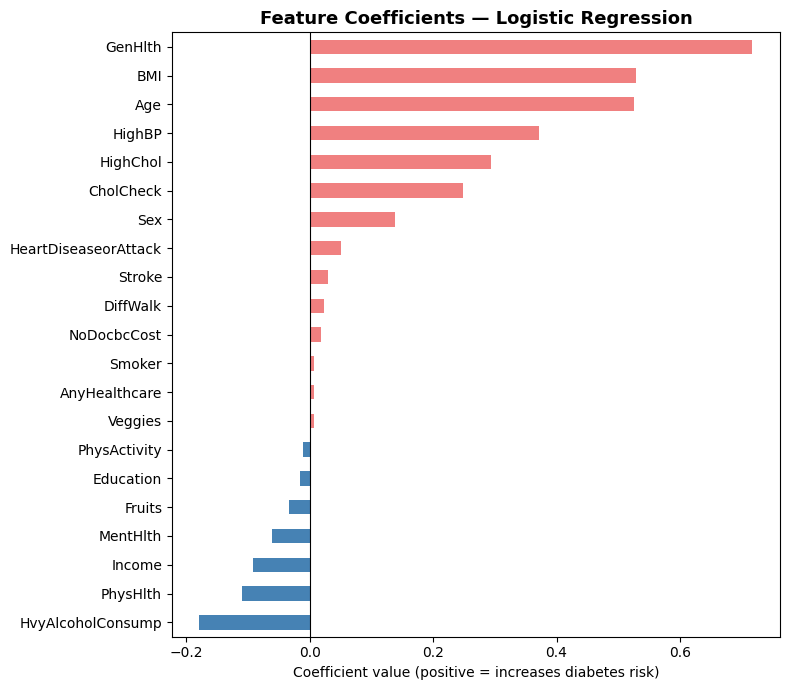

In [ ]:
# logistic regression coefficients
# positive = increases diabetes risk, negative = protective
coefs = pd.Series(lr_model.coef_[0], index=X_raw.columns)
coefs = coefs.sort_values(ascending=True)

# red = increases risk, blue = protective
bar_colors = ['lightcoral' if c > 0 else 'steelblue' for c in coefs]

fig, ax = plt.subplots(figsize=(8, 7))
coefs.plot.barh(ax=ax, color=bar_colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('Feature Coefficients — Logistic Regression', fontsize=13, fontweight='bold')
ax.set_xlabel('Coefficient value (positive = increases diabetes risk)')
plt.tight_layout()
plt.show()

Red bars pushing right increase diabetes risk, blue bars going left are protective. General health, high blood pressure, age and BMI are the strongest risk factors. Heavy alcohol consumption has the biggest negative coefficient which is consistent with the SHAP findings. Education and mental health days are close to zero and have little influence.

### 17. Fairness Check

We need to check whether the model performs equally well across different demographic groups. Big gaps between groups could mean the model is biased against certain populations.

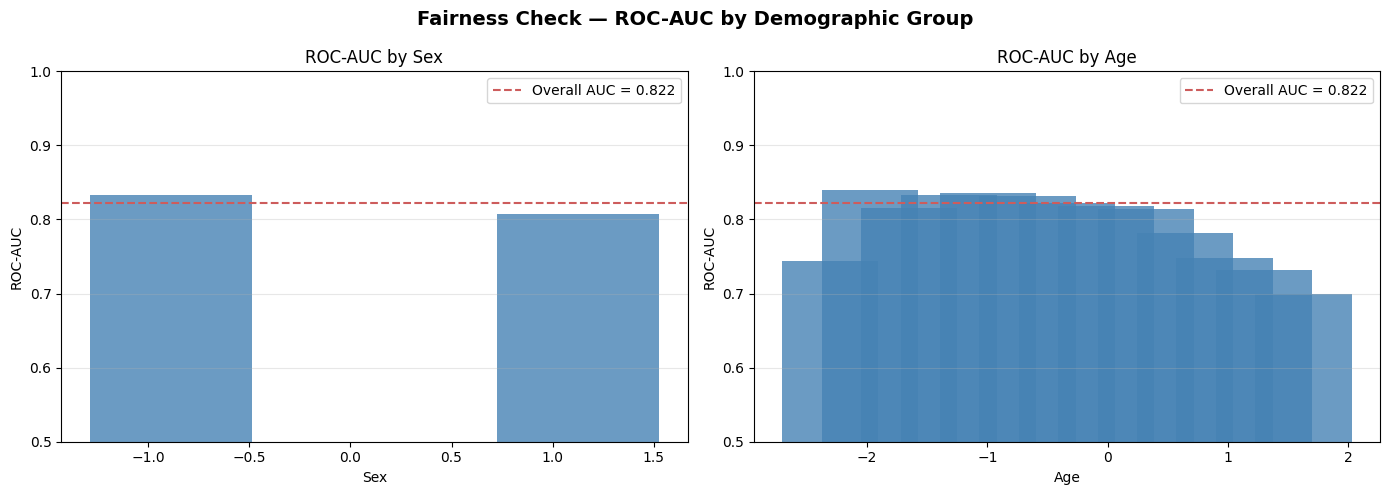

In [ ]:
# checking whether the model performs equally well across different demographic groups

# getting Gradient Boosting probabilities
gb_proba = gb_model.predict_proba(X_test_scaled)[:, 1]

# need a named DataFrame to group by column
X_test_df_fair = pd.DataFrame(X_test_scaled, columns=X_raw.columns)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Fairness Check — ROC-AUC by Demographic Group', fontsize=14, fontweight='bold')

for ax, col in zip(axes, ['Sex', 'Age']):
    groups = sorted(X_test_df_fair[col].unique())
    scores = [
        roc_auc_score(y_test[X_test_df_fair[col] == g], gb_proba[X_test_df_fair[col] == g])
        for g in groups
    ]
    overall_auc = roc_auc_score(y_test, gb_proba)

    ax.bar(groups, scores, color='steelblue', alpha=0.8)
    ax.axhline(y=overall_auc, color='indianred', linestyle='--', label=f'Overall AUC = {overall_auc:.3f}')
    ax.set_title(f'ROC-AUC by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('ROC-AUC')
    ax.set_ylim(0.5, 1.0)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 18. Threshold Tuning

By default, the model predicts diabetes when the predicted probability crosses 0.5. In a healthcare context that's not necessarily the right cutoff, because missing a real diabetic patient is far more dangerous than an unnecessary follow-up. Lowering the threshold means flagging more people as diabetic, which catches more true cases but also increases false alarms.

 Threshold     F1  Recall  Precision
      0.10 0.3751  0.9253     0.2352
      0.15 0.4146  0.8594     0.2732
      0.20 0.4402  0.7840     0.3060
      0.25 0.4525  0.7022     0.3338
      0.30 0.4582  0.6200     0.3634
      0.35 0.4583  0.5441     0.3958
      0.40 0.4392  0.4598     0.4203
      0.45 0.4127  0.3828     0.4476
      0.50 0.3770  0.3116     0.4771
      0.55 0.3222  0.2379     0.4988
      0.60 0.2550  0.1681     0.5282
      0.65 0.1871  0.1122     0.5636
      0.70 0.1138  0.0628     0.6049
      0.75 0.0427  0.0221     0.6527
      0.80 0.0065  0.0033     0.7931
      0.85 0.0000  0.0000     0.0000

Threshold that maximises F1:     0.35  (F1 = 0.4583)
Threshold that maximises Recall: 0.1  (Recall = 0.9253)


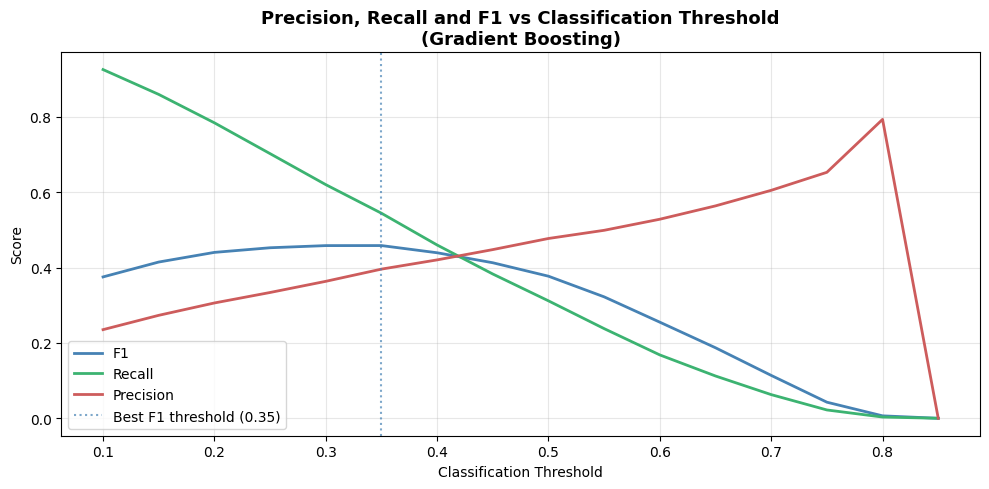

In [ ]:
# Threshold tuning: finding the best cutoff point for clinical use

# By default we label someone as diabetic if that probability exceeds 0.5.
# But in a healthcare context, missing a real diabetic patient (false negative) is far more dangerous than a false alarm (false positive)

# So lowering the threshold means we flag more patients as diabetic so catching more real cases at the cost of more unnecessary follow-ups

# This cell just changes where we draw the line on the probabilities Gradient Boosting already produced earlier (gb_proba)

thresholds = np.arange(0.1, 0.9, 0.05)

threshold_results = []

for t in thresholds:

    # applying the threshold: anyone with predicted probability >= t is labelled diabetic
    preds = (gb_proba >= t).astype(int)

    # recording how precision, recall and F1 change at this cutoff
    threshold_results.append({
        'Threshold': round(t, 2),
        'F1':        round(f1_score(y_test, preds), 4),
        'Recall':    round(recall_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds, zero_division=0), 4)
    })

threshold_df = pd.DataFrame(threshold_results)

# finding the threshold that gives the best F1 score (balance of precision and recall)
# and the threshold that maximises recall (catching the most real diabetic patients)
best_f1_row     = threshold_df.loc[threshold_df['F1'].idxmax()]
best_recall_row = threshold_df.loc[threshold_df['Recall'].idxmax()]

print(threshold_df.to_string(index=False))

print(f"\nThreshold that maximises F1:     {best_f1_row['Threshold']}  (F1 = {best_f1_row['F1']:.4f})")
print(f"Threshold that maximises Recall: {best_recall_row['Threshold']}  (Recall = {best_recall_row['Recall']:.4f})")


# visualising the tradeoff: as threshold decreases, recall goes up but precision drops
# the crossing point of precision and recall is a useful reference
# the vertical line marks the threshold that maximises F1

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(threshold_df['Threshold'], threshold_df['F1'],
        label='F1', color='steelblue', lw=2)

ax.plot(threshold_df['Threshold'], threshold_df['Recall'],
        label='Recall', color='mediumseagreen', lw=2)

ax.plot(threshold_df['Threshold'], threshold_df['Precision'],
        label='Precision', color='indianred', lw=2)

# marking the best F1 threshold as our recommended clinical cutoff
ax.axvline(
    x=best_f1_row['Threshold'],
    color='steelblue',
    linestyle=':',
    alpha=0.7,
    label=f"Best F1 threshold ({best_f1_row['Threshold']})"
)

ax.set_title('Precision, Recall and F1 vs Classification Threshold\n(Gradient Boosting)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Classification Threshold')
ax.set_ylabel('Score')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# evaluating all models at the clinically tuned threshold
# just apply a different cutoff to probabilities that were already computed earlier throughout the notebook

BEST_THRESHOLD = 0.3


all_models_threshold = [
    ('Logistic Regression', lr_model,  X_test_scaled),
    ('KNN',                 knn_model, X_test_scaled),
    ('Decision Tree',       dt_model,  X_test_scaled),
    ('Random Forest',       rf_model,  X_test_scaled),
    ('Gradient Boosting',   gb_model,  X_test_scaled),
    ('SVM (RBF)',           svm_model, X_test_scaled),
]

threshold_comparison = []

for name, model, X_te in all_models_threshold:

    # getting the predicted probabilities each model already learned
    y_proba = model.predict_proba(X_te)[:, 1]

    # applying our tuned threshold instead of the default 0.5
    y_pred_tuned = (y_proba >= BEST_THRESHOLD).astype(int)

    threshold_comparison.append({
        'Model':     name,
        'Recall':    round(recall_score(y_test, y_pred_tuned), 4),
        'Precision': round(precision_score(y_test, y_pred_tuned, zero_division=0), 4),
        'F1':        round(f1_score(y_test, y_pred_tuned), 4),
    })


# displaying results sorted by recall — the most clinically important metric
# a higher recall means fewer real diabetic patients are being missed

threshold_comparison_df = pd.DataFrame(threshold_comparison).set_index('Model')
threshold_comparison_df = threshold_comparison_df.sort_values('Recall', ascending=False)

print(f"All models at threshold = {BEST_THRESHOLD}")
print("Sorted by Recall — catching real diabetic patients is the clinical priority\n")
display(threshold_comparison_df)

All models at threshold = 0.3
Sorted by Recall — catching real diabetic patients is the clinical priority



,Recall,Precision,F1
Model,,,
Logistic Regression,0.9124,0.2422,0.3828
SVM (RBF),0.8622,0.2661,0.4066
KNN,0.8227,0.2383,0.3695
Random Forest,0.8124,0.2878,0.4250
Decision Tree,0.7427,0.2942,0.4214
Gradient Boosting,0.6200,0.3634,0.4582


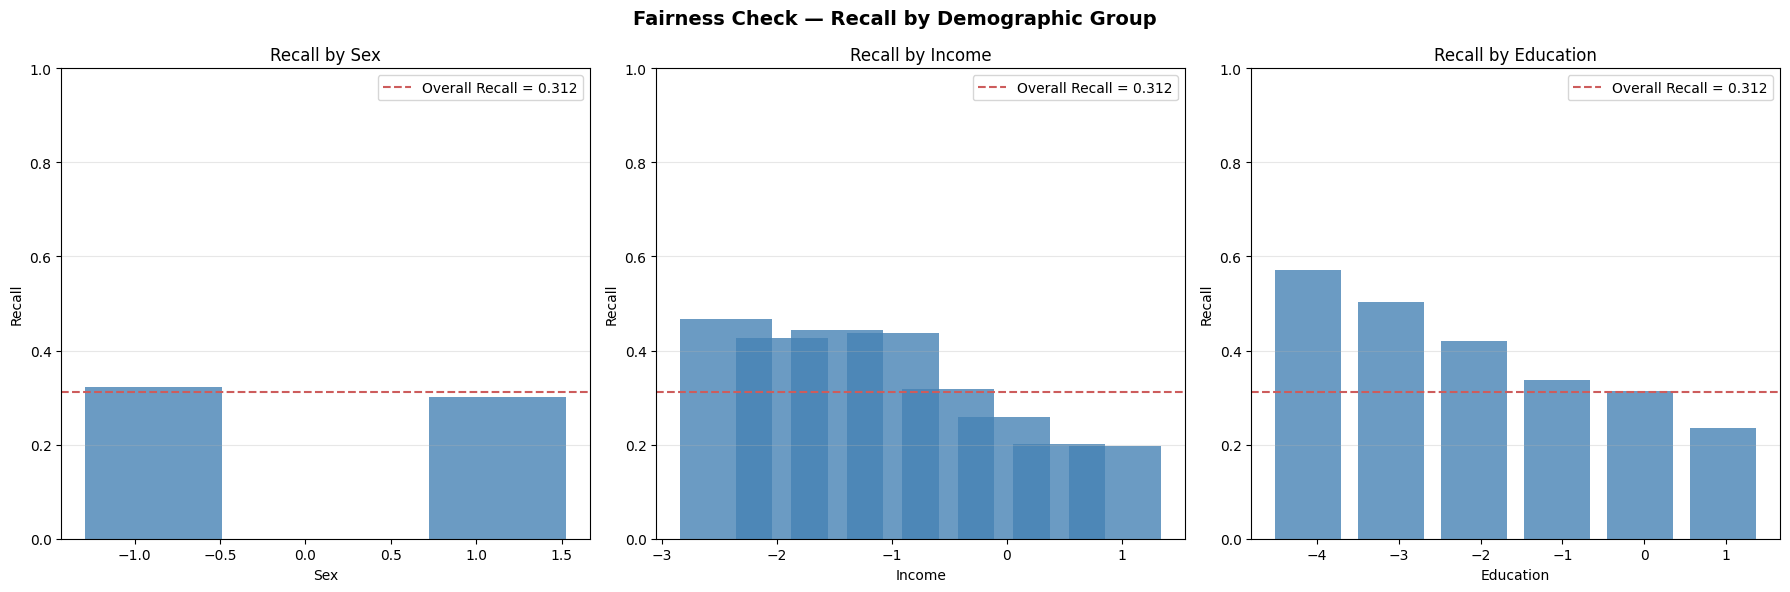

In [ ]:
# getting Gradient Boosting predictions (at default 0.5 threshold)
gb_preds = gb_model.predict(X_test_scaled)

X_test_df_fair = pd.DataFrame(X_test_scaled, columns=X_raw.columns)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Fairness Check — Recall by Demographic Group', fontsize=14, fontweight='bold')

for ax, col in zip(axes, ['Sex', 'Income', 'Education']):
    groups = sorted(X_test_df_fair[col].unique())
    scores = [
        recall_score(y_test[X_test_df_fair[col] == g], gb_preds[X_test_df_fair[col] == g])
        for g in groups
    ]
    overall_recall = recall_score(y_test, gb_preds)

    ax.bar(groups, scores, color='steelblue', alpha=0.8)
    ax.axhline(y=overall_recall, color='indianred', linestyle='--', label=f'Overall Recall = {overall_recall:.3f}')
    ax.set_title(f'Recall by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Recall')
    ax.set_ylim(0, 1.0)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 19. Cross Validation of Classical Models

Cross-validation is placed here at the end of the notebook as it is computationally expensive to run. We re-evaluate all six classical models using 5-fold stratified cross-validation on the SMOTE-balanced training data (not the test set) to give a more stable estimate of generalisation than a single train/test split.

In [ ]:
# 3-fold stratified cross-validation on all classical models
# we run this on the SMOTE-balanced training data — not the test set
# this gives a more stable estimate of generalisation than a single train/test split
# scoring='roc_auc' since we decided earlier that ROC-AUC is our secondary comparison metric

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print("3-Fold Cross Validation ROC-AUC scores:\n")

for name, model in [
    ('Logistic Regression L2', lr_model),
    ('Random Forest',          rf_model),
    ('Gradient Boosting',      gb_model),
]:
    # cross_val_score refits the model on each fold — uses the already-trained model as a template
    scores = cross_val_score(
        model,
        X_train_smote,
        y_train_smote,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    print(f"{name:<25} mean: {scores.mean():.3f}   std: {scores.std():.3f}")